# TACO (T cell Activation from Chemistry and Orientation) — a mechanistic, physics-shaped statistical model of TCR–pMHC activation


**What TACO is.** A ~2,000-parameter model that predicts whether a T-cell
receptor will be *activated* by a peptide presented on MHC. It has no neural network, no
embeddings, no learned representation, no structure prediction and no imported statistical
potential. Every fitted parameter is a contact coupling between a TCR residue type and a peptide
residue type — that is all the data decides. The rest of the model — docking geometry and loop placement — is hand-set from
structural priors, with a small pose selection (seven candidates, scored on validation) adjusting contact widths, loop spacing, and whether loops sweep across the peptide. The fitting itself is penalized logistic
regression on binary labels.
(On signs: the score is a *log-odds*, so a stabilising contact comes out **positive**  — [Model description](#model-words), *Sign convention*.)

**What it is for.** Ranking TCRs against peptides that were *not in training* — in this project,
at least 4 Levenshtein edits away for the peptides from anything fitted. That is the hard case, and it is the only
case measured here. 

| | |
|---|---|
| Transferable fitted parameters | **2,019** — five 20×20 contact potentials (2,000 couplings) + two nine-point exposure profiles (germline and CDR3, 18 control points) + 1 overall bias for calibration|
| Fitted from | seven sequences (6 CDRs and 1 peptide) and one bit (binary label) per row, nothing else |
| Hand-set before any fit | thirteen base geometry constants: six loop centres μ, six sweep slopes ρ, one profile shape κ. A pose selection among seven candidates adjusts some of these; κ is never modified ([Setup](#setup)) |
| Validation file | antigens ≥ 4 Levenshtein edits from training; used for ablation studies ([Ablation](#ablation)) |
| Evaluated on | a holdout file whose antigens are ≥ 4 Levenshtein edits from both training and validation ([Holdout](#holdout)) |

**Scope.** The geometry, the exposure prior, and the training data are all **HLA-A\*02:01**:
diagonal docking polarity, buried anchor positions, an exposed peptide centre. Whether the model
generalises to other class-I alleles is an empirical question, not an assumption.

**Contents**

- [The model in words](#model-words)
  - [Notation](#notation)
  - [Five steps](#five-steps)
  - [Metric](#metric)
- [Setup](#setup)
  - [Constants](#constants)
  - [Where these constants come from](#constants-origin)
- [Encode](#load-encode)
- [Geometry — building S](#geometry)
- [Fit](#fit)
  - [Row groups](#row-groups)
  - [Design](#design)
  - [Scorer, metric and fitter](#scorer)
  - [Objective](#objective)
  - [Fitter verification](#fitter-verification)
  - [Joint fit: profiles, pose, and potentials](#joint-fit)
- [Freeze the model](#freeze)
- [The model as a file](#model-file)
  - [Self-contained scorer](#scorer-class)
  - [Round-trip check](#file-check)
- [Holdout evaluation](#holdout)
- [Comparing across antigens](#cross-antigen)
- [Single inference](#inference)
  - [One record](#one-record)
  - [Ranking](#ranking)
- [What the fitted parameters say](#interpretation)
- [References](#references)
- [Appendix](#appendix)
  - [Ablation](#ablation)
  - [Scaling analysis](#scaling)
  - [Cross-allele generalization](#cross-allele)

---
<a id="model-words"></a>

## The model in words

One row of data is one experiment: *this* TCR, *this* peptide, activated or not. The TCR is six
loops (CDR1α, CDR2α, CDR3α, CDR1β, CDR2β, CDR3β); the peptide is 8–11 residues sitting in the MHC
groove. The model turns that pair into one number, and that number into a probability.

### Structure, pose, geometry

* **Structure** — the qualitative biological picture: class-I / A\*02:01-like diagonal docking,
  the α chain over the peptide's N-terminal half, the β chain over the C-terminal half, the CDR3
  loops reaching in toward the middle.
* **Pose** — one concrete numerical setting built on that picture. Five knobs: `SP` (germline
  spread), `GD` (CDR3 gap), `SIG_G` and `SIG_C` (contact widths), and `SW` (sweep on/off).
  Seven candidates are declared in [Setup](#setup); the [Fit](#fit) section selects the best one
  jointly with the exposure profiles.
* **Geometry** — what you compute once a pose is fixed: the projected loop coordinates
  $x^\ell_i$, the couplings $K^\ell_{ij}$, and the tensors $S^{(r)}[t,j,\alpha]$ that
  everything else is linear in.

![Loop, surface, and exposure-class mapping](images/taco_loop_surface_map.png)

<a id="notation"></a>

### Notation

| symbol | meaning |
|---|---|
| $\ell$ | one of the six TCR loops: CDR1α, CDR2α, CDR3α, CDR1β, CDR2β, CDR3β |
| $L_\ell$ | length of loop $\ell$; its middle residue is $c_\ell = (L_\ell+1)/2$ |
| $i$ | residue index *within* loop $\ell$, running $1,\dots,L_\ell$ |
| $a^\ell_i$ | the amino acid at residue $i$ of loop $\ell$ |
| $j$ | peptide position, running N-terminus → C-terminus; $L_p$ is the peptide length and $b_j$ the residue at $j$ |
| $t$, $p$ | a TCR and a peptide |
| $r$ | one of the five **surfaces** — a set of loops sharing one contact table: `cdr1a`, `cdr2a`, `cdr1b`, `cdr2b`, and `cdr3` (which pools CDR3α and CDR3β) |
| $\alpha$, $\beta$ | amino-acid identities; sums over them run over the 20 standard amino acids. *Not* the TCR chains — those are always spelled out as “α chain” / “β chain”, or appear inside a loop name such as CDR1β |
| $\mu_\ell$ | the loop's centre **in peptide coordinates** — where its middle lands when projected onto the peptide |
| $\rho_\ell$ | sweep slope: peptide positions travelled per residue stepped along the loop |
| $\sigma_\ell$ | contact width: how broadly one projected residue couples to nearby peptide positions (`SIG_G`, `SIG_C`) |
| $\kappa$ | shape of the loop contact profile — how fast it falls off toward the loop's anchored ends |
| $u^\ell_i$ | **loop contact profile**: how much residue $i$ counts, given where it sits along its own loop |
| $K^\ell_{ij}$ | geometric coupling between loop residue $i$ and peptide position $j$ |
| $S^{(r)}[t,j,\alpha]$ | how much amino-acid type $\alpha$ surface $r$ presents at peptide position $j$ |
| $M^{(r)}[\alpha,b_j]$ | fitted contact coupling between TCR residue type $\alpha$ and peptide residue $b_j$ |
| $w_j$ | **exposure profile**: how available peptide position $j$ is — one profile for germline and one profile for CDR3s |
| $z_{tp}$ | the transferable score — a log-odds |
| $b$ | global intercept (one scalar shared across all antigens); not needed for ranking, useful for calibration |

**Two profiles, one per side of the contact.** $u^\ell_i$ and $w^{(c)}_j$ do the same job on
opposite sides of the interface, and reading them as a pair is the quickest way into the model —
but they are not equally free:

| | a profile over | how it is set | fitted numbers |
|---|---|---|---|
| $u^\ell_i$, the loop contact profile | positions *along a TCR loop* | fixed shape, one hand-set parameter κ ([Setup](#setup)) | 0 |
| $w^{(c)}_j$, the exposure profile | positions *along the peptide* | fitted from activation labels ([Exposure profiles](#exposure-profiles)) | 9 control points per class, 18 in all |

![TACO model overview](images/taco_model_overview.png)


<a id="five-steps"></a>

### The five steps

**(1) Place the loops over the peptide.** From the structural picture, each loop gets a centre
$\mu_\ell$ and a sweep slope $\rho_\ell$. Read $\mu$ carefully: it is not a 3-D coordinate of the
loop itself but a **peptide coordinate** — $\mu = 5$ means "the middle of this loop projects onto
peptide position 5". The docking polarity behind these numbers is from the structural literature;
the numbers themselves are ours, hand-written in [Setup](#setup) and put on trial in [Pose scan](#pose).

**(2) Turn placement into contact weights.** Residue $i$ of loop $\ell$ takes its loop contact
profile value $u^\ell_i$, projects onto peptide coordinate $x^\ell_i$, and couples to position $j$
through a Gaussian of width $\sigma_\ell$:

$$u^{\ell}_i \;=\; e^{-\kappa\,(i - c_\ell)^2 / L_\ell},
\qquad c_\ell = \tfrac{L_\ell + 1}{2}$$

$$x^{\ell}_i \;=\; \big(\mu_\ell + \rho_\ell\,(i - c_\ell)\big)\cdot\tfrac{L_p}{9},
\qquad K^{\ell}_{ij} \;=\; e^{-\left(x^{\ell}_i - j\right)^2 / 2\sigma_\ell^{2}}$$

Sum over the residues of each loop, then over the loops belonging to surface $r$:

$$S^{(r)}[t, j, \alpha] \;=\; \sum_{\ell \in r}\ \sum_{i=1}^{L_\ell}
u^{\ell}_i \, K^{\ell}_{ij} \, \mathbb{1}\!\left[a^{\ell}_i = \alpha\right]$$

The $\ell$ superscripts on $u$, $x$ and $K$ are not decoration: all three depend on the loop's own
length, centre and slope, so two loops of different length weight their residues differently.
These tensors are the **sufficient statistic** of the whole model — everything downstream is linear
in them, and they depend only on the TCR sequence and the fixed geometry, never on a label.

**(3) Score the contacts with a contact potential.** For every surface and every peptide position,
add up the contact couplings over the presented types, weighted by how exposed that position is:

$$z_{tp} \;=\; \sum_{r=1}^{5}\ \sum_{j=1}^{L_p} w^{(c(r))}_j
\sum_\alpha S^{(r)}[t, j, \alpha] \, M^{(r)}[\alpha, b_j]$$

$M^{(r)}$ is a free 20×20 table of contact couplings, fitted from our own labels — not BLOSUM, not
a knowledge-based potential. There are **five**, one per surface: each germline loop gets its own,
and CDR3α and CDR3β share one. The four germline loops are V-gene encoded (drawn from a small set of V genes)
and contact the peptide at different positions along the groove, so their amino acid preferences
can genuinely differ. CDR3α and CDR3β are somatically recombined and hypervariable; sharing one
potential is a parsimony choice — whether giving each its own (six total) would help is tested in
[Ablation](#ablation).

**(4) Weight by peptide exposure.** $w^{(c(r))}_j$ says how available peptide position *j* is to the
TCR at all — position 2 and position Ω (the C-terminal anchor) are usually buried in the MHC
pockets, while the centre bulges up. Two profiles are fitted — one for the germline loops and one for CDR3 — nine control
points each (18 total), derived in [Exposure profiles](#exposure-profiles) by alternation.
[Solvent exposure](#solvent) discusses what the resemblance to a solvent-accessibility
profile means.

The profile is a piecewise-linear curve fixed by nine **control points**, one per position of a
9-mer at $x = (j - \tfrac12)/9$, joined by straight lines. On a peptide of length $L_p \neq 9$ the
*same* curve is read off at $x_j = (j - \tfrac12)/L_p$, so a 10-mer costs no new parameters. Nine
is a choice of resolution, not a property of the peptide: enough to separate buried anchors from an
exposed centre, few enough that nine numbers are identifiable from the data. And because $j$ runs
N → C, the profile is *oriented*: the model is not symmetric under reversing the peptide.

Then $\Pr(\text{activation}) = \sigma(z_{tp} + b)$, where $b$ is a single global intercept shared across all antigens.

### Sign convention — why favourable is *positive* here

In physics a stabilising interaction *lowers* the energy, so "more negative" means "more
favourable". That is not what $z$ is. $z$ is a **log-odds**: it goes into a logistic, and larger
$z$ means a larger activation probability. So $M$ carries the sign of $-\Delta\Delta G / k_B T$ — a
contact that would lower the free energy comes out **positive** in these tables and pushes the
probability up. For that reason $M$ is called a contact *coupling* (or interaction score)
throughout this notebook, and never a contact energy: it is an energy divided by $-k_BT$, which is
a different quantity with the opposite sign.

The overall scale is not identified either — multiplying every $M$ by 2 and halving nothing else
would change the fit, but the units of $z$ are logits, not kcal/mol, and the model is never
compared to a measured affinity. Read the tables as *relative* preferences within one potential.

<a id="metric"></a>

### The metric

**Mean per-peptide AUROC**: compute AUROC among the TCRs tested against one antigen, then average
over antigens. *Given this antigen, which of my
TCRs should I test first*.


### Three levels of freedom

* **Hand-set, never searched** — the profile shape κ, the six base loop centres μ_hand, and the six base sweep slopes ρ_hand (one per loop, differing by loop type). These are the starting point; the pose scan can shift or zero them.
* **Selected on validation** — the docking pose, chosen from a grid of seven candidates ([Fit](#fit)). Each pose sets five knobs — SP, GD, SIG_G, SIG_C, SW — that transform the base values into their final form: SP stretches germline μ away from the peptide centre, GD sets the two CDR3 μ symmetrically about position 5, SW scales all six ρ uniformly (the selected pose has SW = 0, zeroing every sweep), and SIG_G / SIG_C set the contact widths σ directly. So the final μ, ρ and σ are *selected*, not hand-set, even though their base values are.
* **Fitted by alternation** (alternate between profile and potential steps, keep the best on validation) — two nine-point exposure profiles (germline and CDR3).
* **Fitted by continuous optimization** (penalized L-BFGS at fixed profiles) — five 20×20 contact tables and one global intercept.

Total: 2,019 transferable parameters (2,000 contact couplings + 18 profile control points + 1 global bias).

---
<a id="setup"></a>

## Setup

### Imports and compute (GPU if available)

In [5]:
import time, math, gc, json, os
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.stats import rankdata

try:
    import torch
    HAVE_GPU = torch.cuda.is_available()
except Exception:
    torch, HAVE_GPU = None, False

print("numpy", np.__version__, "| pandas", pd.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAVE_GPU else "not available (CPU fit, slower)")


numpy 1.23.5 | pandas 1.5.3
GPU: Tesla T4


<a id="paths"></a>

### Data loading

Three local TSV files: training, validation, holdout.

Only the eight columns below are ever read. Anything else in the file does not exist as far as
this notebook is concerned.


#### Paths and relevant columns

In [ ]:
TRAIN_PATH   = "data/train.tsv"
VAL_PATH     = "data/validation.tsv"
HOLDOUT_PATH = "data/holdout.tsv"
MODEL_PATH   = "taco_model.json"

COLS = ["cdr1a", "cdr2a", "cdr3a", "cdr1b", "cdr2b", "cdr3b", "peptide", "label"]


#### Loading datasets and basic checks

In [7]:
df = pd.read_csv(TRAIN_PATH, sep="\t")[COLS]
df_val = pd.read_csv(VAL_PATH, sep="\t")[COLS]
df_holdout = pd.read_csv(HOLDOUT_PATH, sep="\t")[COLS]

def levenshtein(a, b):
    if a == b:
        return 0
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def print_df_summary(name, data):
    n_rows = len(data)
    n_pos = int(data["label"].sum())
    n_antigens = data["peptide"].nunique()

    print(
        f"{name}: {n_rows:,} rows | "
        f"{n_pos:,} positives ({data['label'].mean():.3%}) | "
        f"{n_antigens:,} antigens"
    )


def nearest_antigen_distances(query_peptides, reference_peptides):
    return np.array([
        min(levenshtein(q, p) for p in reference_peptides)
        for q in query_peptides
    ])


def print_distance_check(name, query_peptides, reference_peptides, reference_name):
    dmin = nearest_antigen_distances(query_peptides, reference_peptides)

    counts = "  ".join(
        f"{d}:{int((dmin == d).sum())}"
        for d in sorted(set(dmin.tolist()))
    )

    print(f"\n{name} distance to nearest {reference_name} antigen:")
    print(counts)
    print(f"minimum distance: {dmin.min()}")

    assert dmin.min() >= 4, (
        f"{name} antigens are too close to {reference_name}: "
        f"closest is {dmin.min()} edit(s) away"
    )

    print(f"PASSED -- every {name} antigen is at least 4 edits away from {reference_name}")


print_df_summary("train", df)
print_df_summary("validation", df_val)
print_df_summary("holdout", df_holdout)

train_peptides = df["peptide"].drop_duplicates().tolist()
val_peptides = df_val["peptide"].drop_duplicates().tolist()
holdout_peptides = df_holdout["peptide"].drop_duplicates().tolist()

print_distance_check(
    name="validation",
    query_peptides=val_peptides,
    reference_peptides=train_peptides,
    reference_name="training",
)

train_val_peptides = sorted(set(train_peptides) | set(val_peptides))

print_distance_check(
    name="holdout",
    query_peptides=holdout_peptides,
    reference_peptides=train_val_peptides,
    reference_name="training/validation",
)

train: 5,439,353 rows | 90,000 positives (1.655%) | 500 antigens
validation: 28,750 rows | 5,750 positives (20.000%) | 115 antigens
holdout: 33,500 rows | 6,700 positives (20.000%) | 134 antigens

validation distance to nearest training antigen:
4:68  5:42  6:5
minimum distance: 4
PASSED -- every validation antigen is at least 4 edits away from training

holdout distance to nearest training/validation antigen:
4:84  5:49  6:1
minimum distance: 4
PASSED -- every holdout antigen is at least 4 edits away from training/validation


<a id="constants"></a>

### Constants

We have three kinds of number:

* **Structural priors — hand-set, not fitted.** The amino-acid alphabet, the six base loop centres μ,
  the three distinct sweep slopes ρ (one per loop type), the profile shape κ, and a starting guess
  `W9_PRIOR` for the exposure profile. The pose grid below modifies μ, ρ and σ; κ and `W9_PRIOR`
  are never modified.
* **The pose grid** — seven candidates declared here. The [Fit](#fit) section runs the full
  profile alternation at each one and selects the best (pose, profiles, potentials) triple on
  the validation file.
* **Fitted below.** The two exposure profiles, the five 20×20 contact potentials, and the
  global intercept — all selected jointly with the pose in one combined search.

The ridge `LAMBDA = 1e-6` on the contact potentials is fixed here and never scanned.

In [8]:
AA  = "ARNDCQEGHILKMFPSTWYV"
AAI = {c: i for i, c in enumerate(AA)}

# ---- geometry: (loop, centre on the peptide, sweep slope).  Hand-written, never fitted.
#      alpha chain over the N-terminal half, beta over the C-terminal half, CDR3s in the middle.
#      These centres are the STRUCTURAL guess; the pose scan selects a scale on them.
LOOPS = [("cdr2a", 1.0, 0.30),
         ("cdr1a", 2.5, 0.40),
         ("cdr3a", 3.5, 0.60),
         ("cdr3b", 6.5, 0.60),
         ("cdr1b", 7.5, 0.40),
         ("cdr2b", 9.0, 0.30)]
KAPPA = 1.0     # loop contact profile: how fast contact weight falls off toward a loop's ends

# ---- the five surfaces.  A surface is a set of loops sharing one contact potential: each germline
#      loop gets its own chemistry, and the two CDR3 loops share one table.
SURFACES = [("cdr1a", ["cdr1a"]), ("cdr2a", ["cdr2a"]),
            ("cdr1b", ["cdr1b"]), ("cdr2b", ["cdr2b"]),
            ("cdr3",  ["cdr3a", "cdr3b"])]
GERM_SURF = ["cdr1a", "cdr2a", "cdr1b", "cdr2b"]
CDR3_SURF = ["cdr3"]

# ---- THE POSE GRID, declared before any fit.  A pose is (SP, GD, sigma_germline, sigma_cdr3):
#      germline loop centres are  5 + SP * (mu - 5)  -- SP=1 keeps the hand-written mu, SP>1 pushes
#      the germline loops outward toward the peptide termini;
#      the CDR3 pair sits at  5 -/+ GD  -- symmetric about the peptide centre;
#      sigma is the contact width in peptide positions, one per class.
#      The fit section runs the full profile alternation at each candidate and selects the best
#      (pose, profiles, potentials) triple on the VALIDATION file.
POSE0     = dict(SP=1.0, GD=1.5, SIG_G=1.5, SIG_C=1.5)
POSE_GRID = [
    ("structural guess",     dict(SP=1.0, GD=1.5, SIG_G=1.5, SIG_C=1.5, SW=1.0)),
    ("no sweep",             dict(SP=1.0, GD=1.5, SIG_G=1.5, SIG_C=1.5, SW=0.0)),
    ("wider contacts",       dict(SP=1.0, GD=1.5, SIG_G=2.0, SIG_C=2.0, SW=0.0)),
    ("wider CDR3 only",      dict(SP=1.0, GD=1.5, SIG_G=2.0, SIG_C=2.6, SW=0.0)),
    ("CDR3 pushed apart",    dict(SP=1.0, GD=2.0, SIG_G=2.0, SIG_C=2.6, SW=0.0)),
    ("germline spread 1.4",  dict(SP=1.4, GD=2.0, SIG_G=2.0, SIG_C=2.6, SW=0.0)),
    ("germline spread 1.8",  dict(SP=1.8, GD=2.0, SIG_G=2.0, SIG_C=2.6, SW=0.0)),
]

# ---- exposure profile starting point (positions 2 and 9 are MHC anchors).
#      The fit section alternates from this start and from a flat start; the fitted profiles
#      replace this prior entirely.
W9_PRIOR = np.array([0.35, 0.05, 0.45, 0.85, 1.00, 0.70, 0.85, 0.75, 0.05])

LAMBDA   = 1e-6        # ridge on the contact potentials

print(f"{len(LOOPS)} loops, {len(SURFACES)} surfaces, κ={KAPPA}")
print(f"pose grid: {len(POSE_GRID)} candidates (the fit section scans them jointly with the exposure profiles)")
print("exposure prior (a starting point, not a parameter):", np.round(W9_PRIOR, 2))

6 loops, 5 surfaces, κ=1.0
pose grid: 7 candidates (the fit section scans them jointly with the exposure profiles)
exposure prior (a starting point, not a parameter): [0.35 0.05 0.45 0.85 1.   0.7  0.85 0.75 0.05]


<a id="constants-origin"></a>

### Where these constants come from

The constants in the cell above — the six loop centres μ, the three slopes ρ, the contact
profile shape κ, and the starting guess `W9_PRIOR` — are hand-written from the qualitative
structural picture. Each one is held accountable: the pose grid ([Pose scan](#pose)) puts μ on trial, the SW
switch turns ρ off, the flat-start comparison ([Exposure profiles](#exposure-profiles)) discards `W9_PRIOR` if the data prefers
uniform, and the geometry-deleted control ([Ablation](#ablation)) removes all of them at once.

**(a) Fitted in this notebook, from our own labels.** The two nine-point exposure profiles ([Exposure profiles](#exposure-profiles)),
the five 20×20 contact potentials, and the global intercept.
Nothing is imported: no BLOSUM, no knowledge-based contact matrix, no published potential, and no
constant carried over from anywhere else. Fitting a contact table *from our own activation labels*
is a different thing from importing a statistical potential, and only the former is allowed here.

**(a′) Selected in this notebook, on the validation file.** The pose ([Pose scan](#pose)), the profile start
([Exposure profiles](#exposure-profiles)), and which rung of [Ablation](#ablation)'s ladder is the model. Selection is not fitting — every candidate is
fitted on the same training rows and carries its own parameters — but it is a use of data, and [Data protocol](#three-files)
says what it costs: the validation number for whichever candidate wins is mildly optimistic, and
[Holdout](#holdout)'s holdout is the number that is not. The ridge λ is not selected at all; it is hand-set at
1e-6, like the geometry constants.

**(b) Hand-set structural priors — written down before any fit, and never fitted.** The loop
centres μ, the slopes ρ, the profile shape κ, and the starting profile `W9_PRIOR`.

These are guesses, and the sections below say exactly *what each one claims and what it does not* —
because a guess whose content is left implicit cannot be argued with, and being arguable is the
whole point of writing a mechanistic model instead of a flexible one. Read them expecting to find
that the claims are much weaker than eleven decimal numbers make them look.

#### The six loop centres μ — where each loop sits along the peptide

μ is measured in **peptide positions on a 9-mer**: μ = 1 means "this loop sits over the first
peptide residue", μ = 9 means "over the last", μ = 5 means "over the middle". (On a peptide of
another length the whole picture is rescaled by $L_p/9$, so the loops keep their relative
placement — [Geometry](#geometry).) The six numbers were built in three steps, and only the first is structural.

**Step 1 — fix the *order* of the loops along the peptide.** TCRs dock on class-I pMHC in a
conserved diagonal orientation: the α chain lies over the N-terminal half of the peptide, the β
chain over the C-terminal half. Within each chain, the CDR3 loop is the one that reaches in toward
the middle of the peptide, while the germline CDR1 and CDR2 loops sit **further out**, toward the
peptide's ends and the MHC helices that flank them. Reading N-terminus → C-terminus, that fixes
the order:

```
    N-term                    peptide                    C-term
      |  CDR2a   CDR1a   CDR3a | CDR3b   CDR1b   CDR2b  |
      |<---- alpha chain ----->|<----- beta chain ----->|
```

**This is the one claim in the whole block that needs structural knowledge to judge**, and it is
the one the citations below support. If the polarity is backwards — β over the N-terminal half —
the model is wrong in a way no fitting repairs.

**Step 2 — place the loops symmetrically about the peptide's centre.** Step 1 fixes the order but
says nothing about *how far apart*. We spread the six loops symmetrically across the peptide, in
pairs at equal distances either side of position 5. That is not a structural finding — the two
chains are not known to be mirror images — it is a refusal to invent an asymmetry we have no
evidence for. Any asymmetry we wrote in would be a claim we could not defend, so the symmetric
placement is the conservative one.

**Step 3 — choose the three distances.** CDR3s nearest the centre, CDR1s outside them, CDR2s
furthest out, spread far enough to cover the peptide rather than pile up in the middle:

| loop pair | distance from centre | μ (N-terminal / C-terminal) |
|---|---|---|
| CDR3α / CDR3β | ± 1.5 | 3.5 / 6.5 |
| CDR1α / CDR1β | ± 2.5 | 2.5 / 7.5 |
| CDR2α / CDR2β | ± 4.0 | 1.0 / 9.0 |

**Those three distances are the arbitrary part, and they are the only arbitrary part.** Nothing
above forces ±1.5 rather than ±1.2 or ±1.8. They are one representative member of a whole family
of placements that satisfy steps 1 and 2 equally well, and you are not asked to accept them: [Pose scan](#pose)
turns that family into two knobs — `GD` slides the CDR3 pair in toward the centre or out toward the
ends, `SP` stretches or compresses the germline spread — and scans a grid declared in advance,
fitting a model at each candidate and choosing on the validation file.

#### The three slopes ρ — how much a loop tilts across the peptide

A loop is not a point: it lies at an angle, so as you walk from one end of it to the other you also
travel along the peptide. ρ is that rate, in **peptide positions per loop residue**, and it is what
turns a loop from a dot into a streak. ρ = 0.60 for the CDR3s, 0.40 for the CDR1s, 0.30 for the
CDR2s. Three claims, no more:

* **positive** — every loop runs across the peptide in the same direction, the direction of the
  docking diagonal;
* **less than 1** — a loop is longer than the stretch of peptide it covers, so stepping one residue
  along the loop moves you *less* than one position along the peptide;
* **ordered by loop length** — the long, central CDR3 traverses the most, the short outer CDR2 the
  least.

Beyond that the values are invented. [Pose scan](#pose) accordingly carries a switch, `SW`, that multiplies all
three by **zero**, collapsing every loop from a tilted streak back to a blob centred on μ. A guess
you can switch off and re-measure in the same grid is not something the reader has to take on
trust.

#### κ — the shape of the loop contact profile

A CDR loop is pinned at both ends by the antibody-like framework and bulges out in between, so the
residues in the middle are the ones that reach the peptide and the residues near the anchors are
not. That is the qualitative claim. The **loop contact profile**
$u^{\ell}_i = \exp(-\kappa (i - c_\ell)^2 / L_\ell)$ is how the model states it, and κ is the single
number that says *how fast* the falloff is.

**κ = 1.0 is a unit convention, not a measurement.** The scale of κ is only meaningful together
with the $1/L_\ell$ in the exponent, and the cleanest way to see what the pair asserts is to
evaluate the weight at a loop's *end* residues, where $|i - c_\ell| = (L_\ell - 1)/2$:

| loop | length | weight at the end residues, relative to the middle |
|---|---|---|
| a germline CDR1/CDR2 | 6 | ≈ 35 % |
| a typical CDR3 | 14 | ≈ 5 % |

So κ = 1 with that normalization says something quite specific and quite readable: **short germline
loops touch the peptide fairly evenly along their length, while long CDR3 loops touch it almost
entirely through the handful of residues in the middle.** That sentence is the claim; accept or
reject it rather than the number 1.0.

It also explains why ρ matters less than it looks. The sweep only acts over the residues that carry
appreciable weight — roughly ±3 residues from the middle — so for a 14-residue CDR3 at ρ = 0.60 the
streak is about ±1.8 peptide positions wide, which is the same order as the contact width σ itself.
κ, ρ and σ are three descriptions of one blurred footprint, not three independent commitments.

#### `W9_PRIOR` — the starting guess for the exposure profile

`W9_PRIOR = [0.35, 0.05, 0.45, 0.85, 1.00, 0.70, 0.85, 0.75, 0.05]` claims an **ordering, not
values**: position 2 and the C-terminal position near zero because their side chains are buried in
the MHC's B and F pockets and cannot be touched by a TCR at all; the central positions high because
that is where the peptide bulges up toward the receptor; the rest in between.

The nine numbers themselves are claimed by nobody. This is an *initialization for a fit*, not a
parameter the model keeps: [Exposure profiles](#exposure-profiles) runs the alternation from `W9_PRIOR` **and** from a completely flat
profile and keeps whichever scores better on the validation file, printing both so you can see how
far apart the two starts land. A prior that is doing real work and a prior that is decoration look
different in that print-out, and the notebook shows you which it is rather than asserting it.

#### The citations, and what they do and do not cover

* The conserved diagonal docking orientation, α over the N-terminal half and β over the C-terminal
  half, CDR3s central and germline loops toward the termini and the MHC helices — reviewed in
  Rudolph, Stanfield & Wilson, *How TCRs bind MHCs, peptides, and coreceptors*, **Annu. Rev.
  Immunol.** 24:419–466 (2006), and Garcia & Adams, *How the T cell receptor sees antigen — a
  structural view*, **Cell** 122:333–336 (2005). This is step 1 above.
* Anchoring at P2 and the C-terminus, buried in the B and F pockets, with the central positions
  bulging upward — Falk, Rötzschke, Stevanović, Jung & Rammensee, **Nature** 351:290–296 (1991),
  and standard in every review since. This is the ordering `W9_PRIOR` encodes.

**None of the numbers came from those papers.** μ, ρ, κ and `W9_PRIOR` were not read off any table,
no published solvent-accessibility or contact-frequency dataset was used, and nothing was carried
over from a previous run of this project. The citations support the *qualitative picture* in steps
1 and 3 only; if you intend to quote them, check them yourself.

#### How each guess is held accountable

The argument that these numbers are allowed to be arbitrary does not rest on how well they scored.
It rests on every one of them being declared before the data is touched and then discharged by
construction — and each mechanism is a cell you run, not a claim you accept:

| guess | how it is discharged |
|---|---|
| the three distances in μ | reparameterised as `SP`, `GD` and scanned in [Pose scan](#pose), selected on validation |
| the contact width σ | scanned in the same grid |
| the three slopes ρ | the same grid contains a switch that sets them all to zero |
| κ | a unit convention; its content is the germline-vs-CDR3 contrast above |
| `W9_PRIOR` | refitted in [Exposure profiles](#exposure-profiles), against a flat start, chosen on validation |
| the whole geometry | [Ablation](#ablation) deletes it — σ → ∞, so every loop residue contacts every peptide position equally — and reports what survives |

**Scope.** This geometry is written for **HLA-A\*02:01** docking. Whether it generalises to other
class-I alleles is an empirical question, not an assumption.

**Every performance number in this notebook is printed by a cell in this notebook**, on the files
named in [Setup](#setup), with the metric defined in [Scorer](#scorer) — including the floor and the ablation baselines.
None is a literature value and none is carried in from elsewhere.


---

---
<a id="load-encode"></a>

## Encode

The dataset is a flat table of experiments. Subsetting to the eight permitted columns happens on
the same line as the read, so it is structural rather than something to remember.


<a id="encoding"></a>

### Encoding

Rows share TCRs: each TCR clone is tested against many antigens. So the TCR side is deduplicated
once and everything expensive is computed per *clone*, not per row — that is a ~20× saving on the
geometry build.

`encode()` is written to work on any file with these columns, so the training file, the validation
file and your holdout file all go through exactly the same path. Amino acids outside the standard
20 encode to `-1` and contribute nothing.


In [9]:
LOOP_COLS = [c for c, _, _ in LOOPS]

def seq_to_idx(seqs, Lmax):
    """Sequences -> (n, Lmax) int16 of alphabet indices, -1 for padding/unknown."""
    out = np.full((len(seqs), Lmax), -1, np.int16)
    for r, s in enumerate(seqs):
        for i, c in enumerate(s[:Lmax]):
            out[r, i] = AAI.get(c, -1)
    return out

def encode(df):
    """Everything the model needs from a dataframe, with the TCR side deduplicated."""
    key = (df.cdr3a + "|" + df.cdr3b + "|" +
           df.cdr1a + df.cdr2a + df.cdr1b + df.cdr2b)
    codes, uniq = pd.factorize(key)
    rows_t = codes.astype(np.int32)
    first  = pd.Series(np.arange(len(df))).groupby(rows_t).first().values

    SEQ = {c: df[c].values[first] for c in LOOP_COLS}          # one row per distinct TCR
    LEN = {c: np.array([len(s) for s in SEQ[c]]) for c in LOOP_COLS}
    Lmax = int(max(v.max() for v in LEN.values()))
    IDX = {c: seq_to_idx(SEQ[c], Lmax) for c in LOOP_COLS}

    peps  = sorted(df.peptide.unique())
    pidx  = {p: i for i, p in enumerate(peps)}
    rows_p = df.peptide.map(pidx).values.astype(np.int32)
    LP = np.array([len(p) for p in peps])
    IP = seq_to_idx(np.array(peps), int(LP.max()))

    return dict(n_row=len(df), n_tcr=len(uniq), n_pep=len(peps),
                rows_t=rows_t, rows_p=rows_p, Y=df.label.values.astype(np.int8),
                IDX=IDX, LEN=LEN,
                CONF=(LEN["cdr3a"] + LEN["cdr3b"]).astype(np.float32),   # entropy proxy
                peps=peps, LP=LP, IP=IP, LPS=sorted(set(LP.tolist())))

t0 = time.time()
E = encode(df)
print(f"encoded in {time.time()-t0:.0f}s: {E['n_row']:,} rows / {E['n_tcr']:,} distinct TCRs "
      f"/ {E['n_pep']} antigens")
print("  loop length ranges: " + "  ".join(f"{c} {E['LEN'][c].min()}-{E['LEN'][c].max()}"
                                           for c in LOOP_COLS))
E_VAL = encode(df_val)


encoded in 6s: 5,439,353 rows / 89,929 distinct TCRs / 500 antigens
  loop length ranges: cdr2a 4-8  cdr1a 5-7  cdr3a 4-29  cdr3b 6-24  cdr1b 5-6  cdr2b 5-7


---
<a id="geometry"></a>

## Geometry — building `S`

![Geometry terms: loop centre, sweep slope, and contact width](images/taco_geometry_terms.png)

The figure above defines the per-loop geometry: the centre μ, the contact width σ, the
sharpness κ, and the sweep slope ρ.  A **pose** bundles five parameters (SP, GD, SIG_G,
SIG_C, SW) that transform the hand-set loop constants into placed values — the
[Pose scan](#pose) section selects the best pose from a grid of seven candidates on the
validation file.

Note that the figure above labels ρ = 0.60 as "the model" — that is the hand-set starting
value for a CDR3 loop.  The pose selection sets SW = 0, which zeroes every sweep slope:
in the final model all loops project straight down (ρ = 0).  One possible explanation is
κ: at κ = 1.0 only the central residues of each loop contribute appreciably, so there are
too few effective residues to spread across multiple peptide positions.  A flatter κ would
let more residues reach the peptide, potentially making a non-zero ρ useful.

κ, ρ and the fitted exposure profiles $w_j$ are entangled: all three shape the effective
contact pattern together, and the model can reach similar patterns through different
combinations.  The fitted profiles partially absorb what a different κ or a non-zero ρ
might contribute — for instance, a profile that upweights a loop's central peptide
positions can compensate for too few effective loop residues.  This means SW = 0 could
be a genuine finding or an artefact of κ = 1.0, and the two cannot be fully disentangled
without scanning κ.

![Pose parameters and the selected pose](images/taco_pose_parameters.png)

This section implements steps (1)–(2) of [Model description](#model-words). The code in the next two cells builds the geometry
tensor $S$ from the posed loop centres and a σ value, using the equations defined there.

Two notes on the code. The $L_p/9$ factor in the projection $x^\ell_i$ rescales the standard
9-mer coordinates onto the peptide's actual length, so the same loop table works for 8-mers
through 11-mers. And $S$ is a function of the pose — [Pose scan](#pose) rebuilds it at each candidate;
everything else uses whatever pose is currently set.

$S$ never sees a label and never sees the peptide's identity — only its length. It is the
**sufficient statistic** of the whole model: everything downstream is linear in it, and it
depends only on the TCR sequence and the fixed geometry.


In [10]:
def pose_centres(pose):
    """A pose -> {loop: (posed centre, slope, sigma)}.  This is the entire geometric commitment of
    the model, in one function, so it can be printed and scanned rather than assumed."""
    SP, GD, SW = pose["SP"], pose["GD"], pose.get("SW", 1.0)
    out = {}
    for c, mu, rho in LOOPS:
        m = (5.0 - GD) if c == "cdr3a" else (5.0 + GD) if c == "cdr3b" else 5.0 + SP * (mu - 5.0)
        out[c] = (m, SW * rho, pose["SIG_C"] if c.startswith("cdr3") else pose["SIG_G"])
    return out

def show_pose(pose, label=""):
    pc = pose_centres(pose)
    print(f"  {label:<22}" + "  ".join(f"{c} {pc[c][0]:+5.2f}" for c, _, _ in LOOPS)
          + f"   | sweep x{pose.get('SW', 1.0):.1f}  sigma g/c {pose['SIG_G']}/{pose['SIG_C']}")

print("the pose grid, as placed loop centres on a 9-mer (peptide positions 1..9):")
for label, p in POSE_GRID:
    show_pose(p, label)


the pose grid, as placed loop centres on a 9-mer (peptide positions 1..9):
  structural guess      cdr2a +1.00  cdr1a +2.50  cdr3a +3.50  cdr3b +6.50  cdr1b +7.50  cdr2b +9.00   | sweep x1.0  sigma g/c 1.5/1.5
  no sweep              cdr2a +1.00  cdr1a +2.50  cdr3a +3.50  cdr3b +6.50  cdr1b +7.50  cdr2b +9.00   | sweep x0.0  sigma g/c 1.5/1.5
  wider contacts        cdr2a +1.00  cdr1a +2.50  cdr3a +3.50  cdr3b +6.50  cdr1b +7.50  cdr2b +9.00   | sweep x0.0  sigma g/c 2.0/2.0
  wider CDR3 only       cdr2a +1.00  cdr1a +2.50  cdr3a +3.50  cdr3b +6.50  cdr1b +7.50  cdr2b +9.00   | sweep x0.0  sigma g/c 2.0/2.6
  CDR3 pushed apart     cdr2a +1.00  cdr1a +2.50  cdr3a +3.00  cdr3b +7.00  cdr1b +7.50  cdr2b +9.00   | sweep x0.0  sigma g/c 2.0/2.6
  germline spread 1.4   cdr2a -0.60  cdr1a +1.50  cdr3a +3.00  cdr3b +7.00  cdr1b +8.50  cdr2b +10.60   | sweep x0.0  sigma g/c 2.0/2.6
  germline spread 1.8   cdr2a -2.20  cdr1a +0.50  cdr3a +3.00  cdr3b +7.00  cdr1b +9.50  cdr2b +12.20   | sweep x0

In [ ]:
def loop_S(I, L, mu, rho, Lp, sigma, block=30000):
    """S[t, j, alpha] for one loop.  I is (n_tcr, Lmax) alphabet indices, L the true lengths."""
    nt, Lmax = I.shape
    T = np.zeros((nt, Lp, 20), np.float32)
    i = np.arange(1, Lmax + 1, dtype=np.float32)[None, :]        # loop residue positions
    j = np.arange(1, Lp + 1,  dtype=np.float32)[None, None, :]   # peptide positions
    for s0 in range(0, nt, block):                               # blocked: the (n, Lmax, Lp)
        sl = slice(s0, min(s0 + block, nt))                      # coupling tensor is large
        Lb  = L[sl].astype(np.float32)[:, None]
        ctr = (Lb + 1) / 2
        u = (np.exp(-KAPPA * (i - ctr) ** 2 / Lb) * (i <= Lb)).astype(np.float32)   # loop contact profile
        s = ((mu + rho * (i - ctr)) * (Lp / 9.)).astype(np.float32)                 # projection
        C = u[:, :, None] * np.exp(-((s[:, :, None] - j) ** 2) / (2 * sigma ** 2)).astype(np.float32)
        Ib, Tb = I[sl], T[sl]
        for l in range(Lmax):                    # scatter each loop position onto its amino acid
            col = Ib[:, l]
            for a in range(20):
                m = col == a
                if m.any():
                    Tb[m, :, a] += C[m, l, :]
        T[sl] = Tb
    return T

def build_S(enc, loop_names, pose, sigma_override=None, verbose=False):
    """S for one surface at a given pose: {peptide length -> (n_tcr, Lp, 20)}."""
    pc = pose_centres(pose)
    S = {}
    for Lp in enc["LPS"]:
        acc = np.zeros((enc["n_tcr"], Lp, 20), np.float32)
        for c in loop_names:
            m, rho, sig = pc[c]
            acc += loop_S(enc["IDX"][c], enc["LEN"][c], m, rho, Lp,
                          sig if sigma_override is None else sigma_override)
        S[Lp] = acc
        if verbose:
            print(f"    Lp={Lp}: {acc.nbytes/1e6:.0f} MB", flush=True)
    return S

def build_all_S(enc, pose, surfaces=None, sigma_override=None, label="", quiet=False):
    """The five surfaces at one pose."""
    t0 = time.time()
    S = {name: build_S(enc, loops, pose, sigma_override)
         for name, loops in (surfaces or SURFACES)}
    gb = sum(a.nbytes for s in S.values() for a in s.values()) / 1e9
    if not quiet:
        print(f"  geometry{' ' + label if label else ''}: {len(S)} surfaces, {gb:.1f} GB "
              f"({time.time()-t0:.0f}s)", flush=True)
    return S

def set_geometry(pose, surfaces=None, sigma_override=None, label=""):
    """Build the geometry for BOTH files at one pose, and install it as the current geometry.

    They move together on purpose.  Every fit is scored on the validation file as it is produced
    (the scorer section), so a fit at one pose and a validation geometry at another would silently compare two
    different models.  Keeping the pair in one function is what makes that impossible."""
    global S_TRAIN, S_VAL
    S_TRAIN = build_all_S(E, pose, surfaces, sigma_override, label)
    S_VAL   = build_all_S(E_VAL, pose, surfaces, sigma_override, quiet=True)
    return S_TRAIN, S_VAL

---
<a id="fit"></a>

## Fit

For each candidate pose, fit two exposure profiles (germline and CDR3) by alternation,
which also fits the contact potentials at each step. The best (pose, profiles, potentials)
triple is selected on the validation file.

<a id="row-groups"></a>

### Row groups

The metric and the scoring work antigen by antigen, so rows
are grouped by peptide once and kept that way — for both files.


In [12]:
idx_fit = np.arange(E["n_row"])

def groups(enc, idx):
    """-> (peptide ids, list of row-index arrays), one entry per peptide, stable order."""
    pep = enc["rows_p"][idx]
    o = np.argsort(pep, kind="stable")
    up, st = np.unique(pep[o], return_index=True)
    st = np.append(st, len(o))
    return up, [idx[o[st[i]:st[i + 1]]] for i in range(len(up))]

PEP_FIT, GRP_FIT = groups(E, idx_fit)
PEP_VAL, GRP_VAL = groups(E_VAL, np.arange(E_VAL["n_row"]))
NP_ = len(PEP_FIT)
pfit_index = {p: i for i, p in enumerate(PEP_FIT)}

ROWS_FIT = np.concatenate(GRP_FIT); NF = len(ROWS_FIT)
YFL = E["Y"][ROWS_FIT].astype(np.float64)
PCF = np.concatenate([np.full(len(g), i) for i, g in enumerate(GRP_FIT)])


p0 = YFL.mean(); LOGIT0 = math.log(p0 / (1 - p0))
NULL_NLL = -(p0 * math.log(p0) + (1 - p0) * math.log(1 - p0))
print(f"{NF:,} fit rows / {NP_} antigens   marginal positive rate {p0:.4%}")
print(f"null (one constant) negative log-likelihood      {NULL_NLL:.8f}")


5,439,353 fit rows / 500 antigens   marginal positive rate 1.6546%
null (one constant) negative log-likelihood      0.08427396


<a id="design"></a>

### The design

The score is linear in the contact potentials, so it can be written as one matrix product.
For each row and each surface, accumulate the **contact counts**

$$N[\text{row}, \alpha, \beta] \;=\; \sum_j w_j \, S[t, j, \alpha] \, \mathbb{1}[b_j = \beta]$$

— "how much type α this TCR presents against peptide residues of type β, weighted by exposure".
Then the surface's contribution to the score is exactly $N \cdot \mathrm{vec}(M)$, and with five
surfaces the whole model is one product against a rows × 2,000 design.

**That design is never built.** Written out, it costs 8 GB per million rows and must be
rebuilt whenever the profile or pose changes. The fitter works **matrix-free**: for one peptide
length it forms the antigens' side as a small matrix, multiplies the geometry tensor by it to
score every TCR against every antigen at once, then reads off the pairs the file contains. The
transpose gives the gradient. Both are single matrix products whose size is set by the
repertoire and the antigen panel, so the file may grow without the arithmetic growing with it.

`build_design` still exists below — the explicit matrix is the clearer definition of what the
model *is*, and it is used on a small sample to verify the matrix-free path.

In [ ]:
X9 = (np.arange(1, 10) - .5) / 9

def interp_w(w9, Lp):
    """Nine control points -> weights for a peptide of length Lp.  Identical rule everywhere, so
    a model means the same thing on every file."""
    if Lp == 9:
        return w9.astype(np.float32)
    return np.interp((np.arange(1, Lp + 1) - .5) / Lp, X9, w9).astype(np.float32)

def fill_N(enc, S, w9, grp, out):
    """Contact counts for one surface, written into a preallocated (n_rows, 400) buffer."""
    off = 0
    for g in grp:
        p = enc["rows_p"][g[0]]; Lp = enc["LP"][p]; b = enc["IP"][p, :Lp]
        w = interp_w(w9, Lp)
        G = S[Lp][enc["rows_t"][g]]                       # (n_g, Lp, 20)
        acc = np.zeros((len(g), 20, 20), np.float32)
        for j in range(Lp):
            acc[:, :, b[j]] += G[:, j, :] * w[j]
        out[off:off + len(g)] = acc.reshape(len(g), 400)
        off += len(g)
    return out

def build_design(blocks, grp, n_rows, verbose=True):
    """The explicit design matrix, for an arbitrary grouping of surfaces into contact potentials.

    `blocks` is a list of (surface names, nine-point profile).  Each block gets its own 400
    columns; a block covering two surfaces sums their contact counts, which is exactly what
    "these two surfaces share one potential" means.  This is the DEFINITION of the model's linear
    algebra; nothing is fitted through it, because it does not fit in memory at full size."""
    t0 = time.time()
    D = np.zeros((n_rows, 400 * len(blocks)), np.float32)
    buf = np.empty((n_rows, 400), np.float32)
    for k, (surfs, w9) in enumerate(blocks):
        for name in surfs:
            D[:, 400*k:400*(k+1)] += fill_N(E, S_TRAIN[name], w9, grp, buf)
    if verbose:
        print(f"  design {D.shape[1]//400} block(s), {D.nbytes/1e9:.2f} GB ({time.time()-t0:.0f}s)",
              flush=True)
    return D

def block_geometry(blocks):
    """The matrix-free counterpart of `build_design`: for each peptide length, the geometry of
    every block laid side by side as (n_tcr, K * Lp * 20), with surfaces that share a potential
    already summed.  Indexed by TCR, so its size is set by the repertoire, not by the row count."""
    lps = sorted(S_TRAIN[blocks[0][0][0]].keys())
    return {Lp: np.concatenate([sum(S_TRAIN[n][Lp] for n in surfs).reshape(-1, Lp * 20)
                                for surfs, _ in blocks], 1) for Lp in lps}

PAIR_CAP = 3e7         # (TCR x antigen) scores held at once; sets the chunk size, not the answer

def fit_plan(blocks, grp, cap=PAIR_CAP):
    """The fit, reorganised into a handful of (peptide length, antigen chunk) blocks.

    Inside one block every antigen has the same length, so every row's score is an entry of the
    same `(n_tcr x n_antigen)` table — one dense matrix product, whatever the rows happen to be.
    The rows then enter only as `flat`, an index into that table, and as `rows`, where they sit in
    the fit vector.  This is why doubling the training file does not double the fitting time:
    the arithmetic is sized by the repertoire and the antigen panel, and the rows are a lookup.

    `cap` bounds the table so the chunking is a memory knob, never a change of answer."""
    n_tcr = len(E["CONF"])
    off, offs = 0, []
    for g in grp:
        offs.append(off); off += len(g)
    by_len = {}
    for i, g in enumerate(grp):
        by_len.setdefault(int(E["LP"][E["rows_p"][g[0]]]), []).append(i)
    plan = []
    for Lp in sorted(by_len):
        w  = np.stack([interp_w(w9, Lp) for _, w9 in blocks]).astype(np.float32)
        ids = by_len[Lp]
        step = max(1, int(cap // n_tcr))
        for a0 in range(0, len(ids), step):
            ch = ids[a0:a0 + step]
            plan.append(dict(
                Lp=Lp, w=w, nP=len(ch),
                B=np.stack([E["IP"][E["rows_p"][grp[i][0]], :Lp] for i in ch]).astype(np.int64),
                flat=np.concatenate([E["rows_t"][grp[i]].astype(np.int64) * len(ch) + j
                                     for j, i in enumerate(ch)]),
                rows=np.concatenate([np.arange(offs[i], offs[i] + len(grp[i])) for i in ch]),
                pg=np.concatenate([np.full(len(grp[i]), i, np.int64) for i in ch])))
    return plan


<a id="scorer"></a>

### The scorer, the metric, and the fitter

All three are defined here, before any fitting. Every comparison in this notebook — between
profile starts, between poses, between ablation rungs — uses the same number: mean per-antigen
AUROC on the validation file, computed by `evaluate_res`.

In [ ]:
def score_rows(enc, S_by_surface, model, grp):
    """Transferable score for each row group."""
    out = []
    for g in grp:
        p = enc["rows_p"][g[0]]; Lp = enc["LP"][p]; b = enc["IP"][p, :Lp]
        t = enc["rows_t"][g]
        z = np.zeros(len(g))
        for name, M, w9 in model["surfaces"]:
            w = interp_w(w9, Lp)
            G = S_by_surface[name][Lp][t]                      # (n_g, Lp, 20)
            for j in range(Lp):
                z += (G[:, j, :] @ M[:, b[j]].astype(np.float32)) * w[j]
        out.append(z)
    return out

def auroc_per_peptide(scores, enc, grp):
    """Mean AUROC within antigen -- THE metric.  Antigens with only one class are skipped."""
    per = []
    for si, g in zip(scores, grp):
        y = enc["Y"][g]
        if y.min() == y.max():
            continue
        r = rankdata(si)
        n1, n0 = y.sum(), (1 - y).sum()
        per.append((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
    return float(np.mean(per)), np.array(per)

def auroc_pooled(scores, enc, grp):
    """Secondary descriptor only.  Not comparable with the per-peptide number."""
    s = np.concatenate(scores); y = np.concatenate([enc["Y"][g] for g in grp])
    r = rankdata(s); n1, n0 = y.sum(), (1 - y).sum()
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

<a id="objective"></a>

### The objective

Penalized logistic regression, **convex in the potentials** — one optimum, no initialization story:

$$\mathcal{L}(v) \;=\; \frac{1}{N}\sum_{\text{rows}} \big[\log(1+e^{z}) - z\,y\big] \;+\; \lambda \lVert \mathrm{vec}(M) \rVert^2, \qquad z = N v_M - \bar{N} v_M + b$$

The ridge λ is applied to $M$ itself, not to standardised columns: $M$ is a contact potential
with its own units.

**Collapse guard.** There is a bad solution: the model sets $M = 0$ and predicts the marginal rate
for every row. Every fit checks for this by value.

In [ ]:
def fit_blocks(blocks, tag="", lam=None, maxiter=4000, verbose=True, project=None):
    """Penalised logistic fit of K contact potentials + a global intercept.

    Matrix-free: the design of the design section is never formed.  Each block of `fit_plan` scores every
    (TCR, antigen) pair at one peptide length with a single matrix product and reads the fitted
    rows out of it, so the exact full-batch loss and gradient cost what the repertoire costs, not
    what the file costs.  `project`, if given, is a (400, r) orthonormal basis and confines every
    potential to its span -- the ablation in the signal-survival ladder uses it to build the charge-only model.

    Returns a result dict carrying everything needed to score: the potentials, the profiles they
    were fitted at, the global intercept, and the centring vector."""
    lam = LAMBDA if lam is None else lam
    K, P = len(blocks), 400 * len(blocks)
    t0 = time.time()
    SB, plan = block_geometry(blocks), fit_plan(blocks, GRP_FIT)

    if HAVE_GPU:
        dev = torch.device("cuda")
        SBd = {Lp: torch.from_numpy(np.ascontiguousarray(A)).to(dev) for Lp, A in SB.items()}
        PL  = []
        for c in plan:                                  # one entry per (length, antigen chunk)
            PL.append(dict(Lp=c["Lp"], nP=c["nP"],
                           B=torch.from_numpy(c["B"]).to(dev),
                           Bf=torch.from_numpy(np.ascontiguousarray(c["B"].reshape(-1))).to(dev),
                           w=torch.from_numpy(c["w"]).to(dev),
                           flat=torch.from_numpy(c["flat"]).to(dev),

                           Y=torch.from_numpy(np.ascontiguousarray(YFL[c["rows"]])).to(dev),
                           ))
        Pb  = None if project is None else torch.from_numpy(project).to(dev)
        prj = (lambda x: x) if Pb is None else \
              (lambda x: ((x.reshape(K, 400).float() @ Pb) @ Pb.T).double().reshape(-1))

        def scatter(c, dzr, out):
            """The design's transpose applied to a per-row vector: sum every row's geometry into
            the potentials it touches.  Same two products as the forward pass, run backwards."""
            n_tcr = SBd[c["Lp"]].shape[0]
            DZ = torch.zeros(n_tcr * c["nP"], dtype=torch.float32, device=dev)
            DZ.index_add_(0, c["flat"], dzr)
            gWM = DZ.reshape(n_tcr, c["nP"]).T @ SBd[c["Lp"]]           # (nP, K*Lp*20)
            A = gWM.double().reshape(c["nP"], K, c["Lp"], 20) * c["w"].double()[None, :, :, None]
            out.index_add_(2, c["Bf"], A.permute(1, 3, 0, 2).reshape(K, 20, c["nP"] * c["Lp"]))

        def design_mean():
            """The mean design row -- the centring vector.  Fit rows only."""
            acc = torch.zeros(K, 20, 20, dtype=torch.float64, device=dev)
            for c in PL:
                scatter(c, torch.ones(len(c["flat"]), dtype=torch.float32, device=dev), acc)
            return acc.reshape(-1) / NF

        MUd = design_mean(); MU = MUd.cpu().numpy()

        def obj(v):
            vd = torch.from_numpy(np.ascontiguousarray(v, dtype=np.float64)).to(dev)
            vm = prj(vd[:P]); bias = vd[P]
            Mall = vm.reshape(K, 20, 20).float(); muv = MUd @ vm
            gM  = torch.zeros(K, 20, 20, dtype=torch.float64, device=dev)
            gbias = torch.zeros((), dtype=torch.float64, device=dev)
            loss = torch.zeros((), dtype=torch.float64, device=dev)
            dzsum = loss.clone()
            for c in PL:
                Lp, nP = c["Lp"], c["nP"]
                # every antigen of this chunk, as a design row per (block, position, residue) ...
                WM = (Mall[:, :, c["B"]] * c["w"][:, None, None, :]) \
                        .permute(2, 0, 3, 1).reshape(nP, -1)            # (nP, K*Lp*20)
                # ... scored against every TCR at once, then read at the rows that exist
                Z  = (SBd[Lp] @ WM.T).reshape(-1).index_select(0, c["flat"])
                z  = Z.double() - muv + bias
                y  = c["Y"]
                loss = loss + (torch.clamp(z, min=0) - z*y + torch.log1p(torch.exp(-z.abs()))).sum()
                dzr = torch.sigmoid(z) - y                               # O(1), scaled below
                scatter(c, dzr.float(), gM)
                dz = dzr / NF
                dzsum = dzsum + dz.sum()
                gbias = gbias + dz.sum()
            g = torch.empty_like(vd)
            g[:P]   = prj(gM.reshape(-1) / NF - MUd * dzsum) + 2 * lam * vd[:P]
            g[P] = gbias
            return float((loss / NF + lam * (vd[:P] * vd[:P]).sum()).item()), g.cpu().numpy()
    else:
        def scatter(c, dzr, out):
            """The design's transpose applied to a per-row vector -- the numpy mirror."""
            Lp, nP = c["Lp"], c["nP"]
            n_tcr = SB[Lp].shape[0]
            DZ = np.bincount(c["flat"], weights=dzr, minlength=n_tcr * nP).astype(np.float32)
            gWM = DZ.reshape(n_tcr, nP).T @ SB[Lp]                       # (nP, K*Lp*20)
            A = gWM.astype(np.float64).reshape(nP, K, Lp, 20) * c["w"].astype(np.float64)[None, :, :, None]
            np.add.at(out, (slice(None), slice(None), c["B"].reshape(-1)),
                      A.transpose(1, 3, 0, 2).reshape(K, 20, nP * Lp))

        MU = np.zeros((K, 20, 20))
        for c in plan:
            scatter(c, np.ones(len(c["flat"])), MU)
        MU = MU.reshape(-1) / NF
        prj = (lambda x: x) if project is None else \
              (lambda x: ((x.reshape(K, 400).astype(np.float32) @ project)
                          @ project.T).astype(np.float64).reshape(-1))

        def obj(v):
            vm = prj(v[:P]); bias = v[P]
            Mall = vm.reshape(K, 20, 20).astype(np.float32); muv = MU @ vm
            gM = np.zeros((K, 20, 20)); gbias = 0.0
            loss = dzsum = 0.0
            for c in plan:
                Lp, nP = c["Lp"], c["nP"]
                WM = (Mall[:, :, c["B"]] * c["w"][:, None, None, :]) \
                        .transpose(2, 0, 3, 1).reshape(nP, -1)
                Z  = (SB[Lp] @ WM.T).reshape(-1)[c["flat"]]
                z  = Z.astype(np.float64) - muv + bias
                y  = YFL[c["rows"]]
                loss += (np.maximum(z, 0) - z*y + np.log1p(np.exp(-np.abs(z)))).sum()
                dzr = 1. / (1. + np.exp(-z)) - y
                scatter(c, dzr, gM)
                dz = dzr / NF
                dzsum += dz.sum()
                gbias += dz.sum()
            g = np.empty_like(v)
            g[:P]   = prj(gM.reshape(-1) / NF - MU * dzsum) + 2 * lam * v[:P]
            g[P] = gbias
            return loss / NF + lam * (v[:P] @ v[:P]), g

    v0 = np.zeros(P + 1); v0[P] = LOGIT0        # start from the marginal rate
    r = minimize(obj, v0, jac=True, method="L-BFGS-B",
                 options={"maxiter": maxiter, "maxfun": 3*maxiter, "ftol": 1e-13, "gtol": 1e-9})
    if HAVE_GPU:
        del SBd, PL, MUd; torch.cuda.empty_cache()
    del SB; gc.collect()

    vfin = r.x[:P] if project is None else \
        ((r.x[:P].reshape(K, 400).astype(np.float32) @ project) @ project.T).reshape(-1)
    res = dict(tag=tag, nll=float(r.fun), nit=int(r.nit), mu=MU,
               Ms=[np.asarray(vfin[400*k:400*(k+1)], np.float64).reshape(20, 20) for k in range(K)],
               ws=[w9.copy() for _, w9 in blocks],
               surfs=[list(s) for s, _ in blocks],
               bias=float(r.x[P]),
               collapsed=abs(r.fun - NULL_NLL) < 1e-5 or np.abs(vfin).max() < 1e-8,
               capped=r.nit >= maxiter)
    res.update(evaluate_res(res))
    if verbose:
        print(f"    [{tag:<44}] fit nll {res['nll']:.8f}   val AUROC {res['val']:.4f} (overall {res['val_pooled']:.4f})   "
              f"{res['nit']:>4} it {time.time()-t0:5.0f}s"
              + ("   *** COLLAPSED ***" if res["collapsed"] else "")
              + ("   *** ITERATION CAP ***" if res["capped"] else ""), flush=True)
    return res

def as_model(res):
    """A result dict -> the MODEL shape `score_rows` consumes.  A block covering two surfaces
    appears as two entries sharing one potential and one profile."""
    surfaces = [(name, res["Ms"][k], res["ws"][k])
                for k, names in enumerate(res["surfs"]) for name in names]
    return dict(surfaces=surfaces)

def evaluate_res(res):
    """Mean per-antigen AUROC on the VALIDATION file -- the one quantity anything is selected on.

    It is computed here, as each fit finishes, rather than in a separate evaluation pass, because
    that is what makes every comparison in sections 6.5, 8 and 9 the same comparison: same scorer,
    same metric, same rows, no chance of two candidates being measured differently.

    `S_VAL` is the validation geometry at the CURRENT pose, kept in step with `S_TRAIN` by
    `set_geometry`."""

    sc = score_rows(E_VAL, S_VAL, as_model(res), GRP_VAL)
    return dict(val=auroc_per_peptide(sc, E_VAL, GRP_VAL)[0],
                val_pooled=auroc_pooled(sc, E_VAL, GRP_VAL))

def z_matrix_free(blocks, grp, Ms):
    """The fitter's forward arithmetic, in isolation: the score of every row in `grp`, computed
    from the geometry tensor without a design matrix.  Same expressions as `fit_blocks`."""
    SB = block_geometry(blocks)
    Mall = np.stack(Ms).astype(np.float32)
    out = np.empty(sum(len(g) for g in grp))
    for c in fit_plan(blocks, grp):
        Lp, nP = c["Lp"], c["nP"]
        WM = (Mall[:, :, c["B"]] * c["w"][:, None, None, :]).transpose(2, 0, 3, 1).reshape(nP, -1)
        out[c["rows"]] = (SB[Lp] @ WM.T).reshape(-1)[c["flat"]].astype(np.float64)
    return out

<a id="fitter-verification"></a>

### Fitter verification

We take a handful of antigens, build the
explicit design for them the slow way, multiply it by a random set of potentials, and compare
against the matrix-free arithmetic on the same rows and the same potentials.

Random potentials rather than fitted ones, deliberately — a fitted $M$ is smooth and could hide a
disagreement that a rough one exposes.


In [16]:
set_geometry(POSE0, label="for verification")

_bl  = [([name], W9_PRIOR) for name, _ in SURFACES]
_grp = GRP_FIT[:8]
_Ms  = [np.random.default_rng(3 + k).normal(size=(20, 20)) for k in range(len(_bl))]

_D  = build_design(_bl, _grp, sum(len(g) for g in _grp), verbose=False)
_zd = _D @ np.concatenate([M.ravel() for M in _Ms]).astype(np.float32)
_zf = z_matrix_free(_bl, _grp, _Ms)
_rel = np.abs(_zd - _zf).max() / np.abs(_zd).max()

print(f"{_D.shape[0]:,} rows x {_D.shape[1]} design columns, {len(_bl)} surfaces")
print(f"explicit design vs matrix-free: max relative difference {_rel:.2e}")
print("MATCH -- the fitter optimises the model defined above"
      if _rel < 1e-5 else "MISMATCH -- the matrix-free path is not the design product")
del _D, _zd, _zf, S_TRAIN, S_VAL; gc.collect()


  geometry for verification: 5 surfaces, 1.1 GB (12s)
96,752 rows x 2000 design columns, 5 surfaces
explicit design vs matrix-free: max relative difference 4.89e-07
MATCH -- the fitter optimises the model defined above


20

<a id="joint-fit"></a>

### Joint fit: exposure profiles, pose, and contact potentials

The exposure profile $w_j$ — how available peptide position $j$ is to the TCR — is a piecewise-linear
curve fixed by nine control points.  Germline loops and CDR3 loops get separate profiles, because
they sit at different ends of the peptide and see different pockets.

The score is bilinear in the control points and the potentials, so the fit alternates between two
convex steps.  Two stages: first one shared potential and one profile to get a warm start (Stage A
decides nothing), then five independent potentials (one per surface) with two exposure profiles
(germline and CDR3).  Two starts per stage (prior and flat) test whether the
starting guess matters; the best on validation is kept.

**Profiles and pose are coupled** — the optimal exposure profile depends on the contact geometry,
and vice versa.  Rather than fitting profiles at one pose and then scanning poses with frozen
profiles or viceversa, the cell below runs the full alternation at every candidate pose and selects the best
(pose, profiles, potentials) triple on the validation file.  The winning result already carries
the fitted potentials — no separate potential-fitting step is needed.

**What the profile is and is not.** $w_j$ is fitted from activation labels alone — no solvent
accessibility was measured or imported. It reflects how available each peptide position is to the
TCR, which correlates with solvent exposure (buried anchor residues score low, the central bulge
scores high) but also absorbs the docking geometry and dataset composition. Two profiles rather
than one means $w$ includes the reach of each loop class, not just a property of the peptide.

In [ ]:
GERM = GERM_SURF
CDR3 = CDR3_SURF
ALL6 = GERM + CDR3

def ctrl_matrix(Lp):
    """A[j, k] = d(w_j)/d(ctrl_k).  Linear interpolation is linear in the control points, so the
    whole map from nine control points to length-Lp weights is this one matrix."""
    return np.stack([interp_w(np.eye(9)[k], Lp) for k in range(9)], 1).astype(np.float64)

CMAT = {Lp: ctrl_matrix(Lp) for Lp in E["LPS"]}

def fill_G(surfs, M, grp, n_rows):
    """d(score)/d(ctrl_k) for one class at fixed potential -- the profile step's design.

    Built with the same all-pairs arithmetic as the potential step: for one peptide length and one
    peptide position, every TCR is scored against every antigen of the chunk with one 20-wide
    matrix product, and the rows that exist are read out of it.  Nine columns per class, so this
    design does fit in memory -- it is the *making* of it that used to cost, once per profile step
    and once per class."""
    ones = np.ones(9)
    SB   = block_geometry([(surfs, ones)])
    plan = fit_plan([(surfs, ones)], grp)
    if HAVE_GPU:
        dev = torch.device("cuda")
        Mt  = torch.from_numpy(M.astype(np.float32)).to(dev)
        S3  = {Lp: torch.from_numpy(np.ascontiguousarray(A)).to(dev).reshape(-1, Lp, 20)
               for Lp, A in SB.items()}
        Ad  = {Lp: torch.from_numpy(CMAT[Lp].astype(np.float32)).to(dev) for Lp in SB}
        G   = torch.zeros(n_rows, 9, device=dev)
        for c in plan:
            Lp = c["Lp"]
            Mb = Mt[:, torch.from_numpy(c["B"]).to(dev)]                    # (20, nP, Lp)
            fl = torch.from_numpy(c["flat"]).to(dev)
            Ec = torch.empty(len(c["rows"]), Lp, device=dev)
            for j in range(Lp):
                Ec[:, j] = (S3[Lp][:, j, :] @ Mb[:, :, j]).reshape(-1).index_select(0, fl)
            G.index_copy_(0, torch.from_numpy(c["rows"]).to(dev), Ec @ Ad[Lp])
        del S3, Ad; torch.cuda.empty_cache()
        return G
    vm = M.astype(np.float32); G = np.zeros((n_rows, 9))
    for c in plan:
        Lp = c["Lp"]
        S3 = SB[Lp].reshape(-1, Lp, 20)
        Mb = vm[:, c["B"]]
        Ec = np.empty((len(c["rows"]), Lp), np.float32)
        for j in range(Lp):
            Ec[:, j] = (S3[:, j, :] @ Mb[:, :, j]).reshape(-1)[c["flat"]]
        G[c["rows"]] = Ec @ CMAT[Lp].astype(np.float32)
    return G

def fit_profile(res, shared, w_start=None, Gs=None):
    """Profile step.  `shared=True` fits nine control points used by every class; False fits one
    set per class.  Convex at fixed potentials.  Returns one renormalised profile per class.
    `w_start` overrides where the search begins (the potential and the profile can come from
    different places -- that is exactly what a seeded alternation is)."""
    if Gs is None:
        Gs = [fill_G(res["surfs"][k], res["Ms"][k], GRP_FIT, NF) for k in range(len(res["Ms"]))]
    n_prof = len(Gs)
    cat = (lambda L: torch.cat(L, 1)) if HAVE_GPU else np.hstack
    G  = sum(Gs) if shared else cat(Gs)
    del Gs; gc.collect()
    k  = G.shape[1]

    if HAVE_GPU:                    # same split as the potential step: float32 product, float64
        dev = torch.device("cuda")  # elementwise, so the two fits agree on precision as well
        Gd  = G                                        # built on the device already
        MGd = Gd.sum(0, dtype=torch.float64) / NF      # the centring row, in float64
        mu_g = MGd.cpu().numpy()
        Yd  = torch.from_numpy(np.ascontiguousarray(YFL)).to(dev)


        def obj(v):
            vd = torch.from_numpy(np.ascontiguousarray(v)).to(dev)
            w, bias = vd[:k], vd[-1]
            z = (Gd @ w.float()).double() - (MGd @ w) + bias
            loss = (torch.clamp(z, min=0) - z*Yd + torch.log1p(torch.exp(-z.abs()))).sum() / NF
            dz = (torch.sigmoid(z) - Yd) / NF
            g = torch.empty_like(vd)
            g[:k]   = (Gd.T @ dz.float()).double() - MGd * dz.sum()
            g[-1] = dz.sum()
            return float(loss.item()), g.cpu().numpy()
    else:
        mu_g = G.mean(0)

        def obj(v):
            w, bias = v[:k], v[-1]
            z = G @ w - mu_g @ w + bias
            loss = (np.maximum(z, 0) - z*YFL + np.log1p(np.exp(-np.abs(z)))).sum() / NF
            dz = (1. / (1. + np.exp(-z)) - YFL) / NF
            g = np.empty_like(v)
            g[:k] = G.T @ dz - mu_g * dz.sum()
            g[-1] = dz.sum()
            return loss, g
    ws0 = res["ws"] if w_start is None else w_start
    w0  = ws0[0] if shared else np.concatenate(ws0)
    v0  = np.append(w0, LOGIT0)
    r = minimize(obj, v0, jac=True, method="L-BFGS-B",
                 options={"maxiter": 2000, "ftol": 1e-13, "gtol": 1e-9})
    if HAVE_GPU:
        del Gd, MGd, Yd; torch.cuda.empty_cache()
    del G; gc.collect()
    nrm = lambda w: w / np.abs(w).max()          # the scale is degenerate with M; fix it here
    if shared:
        return [nrm(r.x[:9])] * n_prof
    return [nrm(r.x[9*i:9*(i+1)]) for i in range(n_prof)]

def grouped_Gs(res, prof_map):
    """Build one design matrix per profile class by summing fill_G over surfaces that share it."""
    K_profiles = max(prof_map) + 1
    Gs = [None] * K_profiles
    for k, p in enumerate(prof_map):
        Gk = fill_G(res["surfs"][k], res["Ms"][k], GRP_FIT, NF)
        Gs[p] = Gk if Gs[p] is None else Gs[p] + Gk
        del Gk
    return Gs

def extract_ws(ws, prof_map):
    """K_potentials profiles -> K_profiles: take the first occurrence of each class."""
    K_profiles = max(prof_map) + 1
    first = {}
    for k, p in enumerate(prof_map):
        if p not in first:
            first[p] = k
    return [ws[first[p]] for p in range(K_profiles)]

def expand_ws(ws_prof, prof_map):
    """K_profiles profiles -> K_potentials: duplicate via prof_map."""
    return [ws_prof[p].copy() for p in prof_map]

def fit_at(pot_classes, ws, tag):
    """One potential step: fit the contact potentials at these profiles."""
    return fit_blocks(list(zip(pot_classes, ws)), tag=tag)

def alternate(tag, pot_classes, w_init, shared, prof_map=None, iters=3, seed=None):
    """Alternate potential step and profile step, keeping the iterate that scores best on the
    VALIDATION file -- which is what makes a non-convex schedule an honest one rather than a hope.

    pot_classes:  K_potentials surface groups, one potential fitted per group.
    prof_map:     optional list of length K_potentials mapping each potential index to a profile
                  class (0..K_profiles-1).  When set, the profile step fits K_profiles independent
                  profiles and expands them back to K_potentials for the next potential step.
                  When None, K_profiles = K_potentials (identity).

    With `seed` (a fitted result), the profile step goes first, at the seed's potential; the two
    starts then differ only in their initial profile and share the seed.  Without it, the
    potential step goes first, which is what makes sense once a previous stage has already
    supplied fitted profiles."""

    def _profile_step(res, ws):
        if prof_map is None:
            return fit_profile(res, shared, ws)
        Gs = grouped_Gs(res, prof_map)
        ws_prof = fit_profile(res, shared, extract_ws(ws, prof_map), Gs=Gs)
        return expand_ws(ws_prof, prof_map)

    ws = [w.copy() for w in w_init]; best = None; prev = seed
    for it in range(iters):
        if prev is not None:
            ws = _profile_step(prev, ws)
        res = fit_at(pot_classes, ws, f"{tag} it{it+1}")
        if best is None or res["val"] > best["val"]:
            best = res
        if seed is not None:
            prev = res
        else:
            ws = _profile_step(res, ws)
    return best


In [18]:
SURF5 = [[s] for s, _ in SURFACES]
PROF_MAP = [0 if s in GERM_SURF else 1 for s, _ in SURFACES]
K_POTENTIALS = len(SURF5)
K_PROFILES = max(PROF_MAP) + 1

print(f"K_potentials = {K_POTENTIALS}, K_profiles = {K_PROFILES}")
print(f"prof_map = {PROF_MAP}")

T_TOTAL = time.time()
POSE_RESULTS = []

for pose_label, pose_cand in POSE_GRID:
    T0 = time.time()
    print(f"\n{'='*100}")
    print(f"POSE: {pose_label}")
    print(f"{'='*100}")
    set_geometry(pose_cand, label=f"[{pose_label}]")

    # Stage A: one potential over all six loops, one shared profile (warm start for stage B)
    A_seed  = fit_at([ALL6], [W9_PRIOR], f"  A seed ({pose_label})")
    A_prior = alternate(f"  A prior ({pose_label})", [ALL6], [W9_PRIOR], shared=True, seed=A_seed)
    A_flat  = alternate(f"  A flat  ({pose_label})", [ALL6], [np.ones(9)], shared=True, seed=A_seed)
    A_best  = max([A_prior, A_flat], key=lambda r: r["val"])
    W_A = A_best["ws"][0]

    # Stage B: K_POTENTIALS independent potentials, K_PROFILES profile classes
    W_B = expand_ws([W_A] * K_PROFILES, PROF_MAP)
    B_warm  = alternate(f"  B warm ({pose_label})", SURF5, W_B,
                        shared=False, prof_map=PROF_MAP)
    B_prior = alternate(f"  B prior ({pose_label})", SURF5,
                        expand_ws([W9_PRIOR] * K_PROFILES, PROF_MAP),
                        shared=False, prof_map=PROF_MAP)
    best_B = max([B_warm, B_prior], key=lambda r: r["val"])
    best_B["pose"] = dict(pose_cand)
    best_B["pose_label"] = pose_label

    POSE_RESULTS.append(best_B)
    print(f"  -> {pose_label}: {K_POTENTIALS}-pot/{K_PROFILES}-prof {best_B['val']:.4f}  "
          f"  {(time.time()-T0)/60:.0f} min")
    del S_TRAIN, S_VAL; gc.collect()

# Select the best (pose, profiles, potentials) triple
FIT = max(POSE_RESULTS, key=lambda r: r["val"])
POSE = FIT["pose"]

# Rebuild geometry at the selected pose (everything below uses it)
set_geometry(POSE, label="at the SELECTED pose")

print(f"\n{'='*100}")
print(f"RESULT")
print(f"{'='*100}")
print(f"\n{'pose':<24}{f'{K_POTENTIALS}-pot/{K_PROFILES}-prof':>16}")
for r in POSE_RESULTS:
    sel = "  <- SELECTED" if r is FIT else ""
    print(f"{r['pose_label']:<24}{r['val']:>16.4f}{sel}")

show_pose(POSE, "selected pose")
N_TRANSFERABLE = K_POTENTIALS * 400 + K_PROFILES * 9 + 1  # +1 for global bias
print(f"\ntransferable parameters: {N_TRANSFERABLE}  "
      f"({K_POTENTIALS} potentials x 400 + {K_PROFILES} profiles x 9 + 1 bias)")
print(f"validation AUROC: {FIT['val']:.4f}  (overall: {FIT['val_pooled']:.4f})")
print(f"fit nll: {FIT['nll']:.8f}")

print(f"\ntotal elapsed: {(time.time()-T_TOTAL)/60:.0f} min")

W_PROFILES = extract_ws(FIT["ws"], PROF_MAP)
_prof_labels = ["germline", "CDR3"]
print("\n" + "-"*92)
print(f"{'position':<20}" + " ".join(f"{j+1:>5}" for j in range(9)))
print(f"{'structural prior':<20}" + " ".join(f"{x:5.2f}" for x in W9_PRIOR))
for p, w in enumerate(W_PROFILES):
    lbl = _prof_labels[p] if p < len(_prof_labels) else f"class {p}"
    print(f"{lbl:<20}" + " ".join(f"{x:5.2f}" for x in w))
print("-"*92)
print("These vectors are the model's answer to 'which peptide positions can the TCR see'.")
print("MHC anchor positions (2 and the C-terminus) should come out LOW.")
for p, w in enumerate(W_PROFILES):
    lbl = _prof_labels[p] if p < len(_prof_labels) else f"class {p}"
    r2 = int(np.argsort(np.argsort(w))[1]) + 1
    print(f"  {lbl:<12} position 2: {w[1]:.2f}  (rank {r2}/9)")


K_potentials = 5, K_profiles = 2
prof_map = [0, 0, 0, 0, 1]

POSE: structural guess
  geometry [structural guess]: 5 surfaces, 1.1 GB (13s)
    [  A seed (structural guess)                 ] fit nll 0.08196890   val AUROC 0.6279 (overall 0.6323)    407 it    16s
    [  A prior (structural guess) it1            ] fit nll 0.08150604   val AUROC 0.6372 (overall 0.6437)    366 it    15s
    [  A prior (structural guess) it2            ] fit nll 0.08139932   val AUROC 0.6371 (overall 0.6444)    296 it    11s
    [  A prior (structural guess) it3            ] fit nll 0.08137606   val AUROC 0.6365 (overall 0.6440)    316 it    12s
    [  A flat  (structural guess) it1            ] fit nll 0.08150604   val AUROC 0.6372 (overall 0.6437)    342 it    13s
    [  A flat  (structural guess) it2            ] fit nll 0.08139932   val AUROC 0.6372 (overall 0.6444)    349 it    14s
    [  A flat  (structural guess) it3            ] fit nll 0.08137607   val AUROC 0.6365 (overall 0.6440)    327 it    12s

---
<a id="freeze"></a>

## Freeze the model

The fit above selected the best (pose, profiles, potentials) triple.  This section bundles
the result into `MODEL` — the single object that evaluation, holdout, and inference all read.

In [19]:
MODEL = dict(
    surfaces=[(name, FIT["Ms"][k], FIT["ws"][k])
              for k, names in enumerate(FIT["surfs"]) for name in names],
    pose=dict(POSE),
    bias=FIT["bias"],
)
print(f"MODEL: {len(MODEL['surfaces'])} surfaces, {N_TRANSFERABLE} transferable parameters")
show_pose(MODEL["pose"], "selected pose")
print(f"validation AUROC: {FIT['val']:.4f}  (overall: {FIT['val_pooled']:.4f})")
print(f"global bias: {FIT['bias']:.6f}")


MODEL: 5 surfaces, 2019 transferable parameters
  selected pose         cdr2a +1.00  cdr1a +2.50  cdr3a +3.00  cdr3b +7.00  cdr1b +7.50  cdr2b +9.00   | sweep x0.0  sigma g/c 2.0/2.6
validation AUROC: 0.6999  (overall: 0.7154)
global bias: -4.535557


---
<a id="model-file"></a>

## The model as a file

The fitted model is written to a JSON file containing the potentials, the profiles, and the
resolved docking geometry — everything needed to score. The self-contained scorer (`TACOModel`)
re-derives the contact geometry from the amino-acid sequences and the file's constants, with no
reference to anything above it.

---

In [ ]:
def to_spec(model, label, extra=None):
    """A fitted model -> the plain dict of numbers that gets written to disk.

    The pose is *resolved* here into per-loop geometry (centre, slope, contact width), so a reader
    never has to know what `SP` or `GD` meant, or which grid they came from."""
    defs = dict(model.get("surfaces_def", SURFACES))
    pc   = pose_centres(model["pose"])
    ovr  = model.get("sigma_override")
    return dict(
        format="taco-model-1",
        label=label,
        alphabet=AA,
        kappa=float(KAPPA),
        loops={c: dict(centre=float(pc[c][0]), slope=float(pc[c][1]),
                       sigma=float(pc[c][2] if ovr is None else ovr))
               for c, _, _ in LOOPS},
        surfaces=[dict(name=n, loops=list(defs[n]),
                       M=np.asarray(M, float).round(8).tolist(),
                       w9=np.asarray(w9, float).round(8).tolist())
                  for n, M, w9 in model["surfaces"]],
        pose=dict(model["pose"]),
        bias=float(model.get("bias", 0.0)),
        provenance=extra or {})

SPEC = to_spec(MODEL, "full", extra=dict(
    training_file=TRAIN_PATH, fit_rows=int(NF), fit_antigens=int(NP_), ridge=LAMBDA,
    validation_file=VAL_PATH, validation_auroc=round(float(FIT["val"]), 6),
    validation_auroc_is_optimistic="this model was selected on that file; see the holdout section "
                                   "for a number nothing was selected on",
    transferable_parameters=int(N_TRANSFERABLE),
    metric="mean AUROC within antigen",
    note="scores are transferable log-odds with a single global intercept; they are directly "
         "comparable across antigens"))

import json as _json
with open(MODEL_PATH, "w") as _fh:
    _json.dump(SPEC, _fh, indent=1)
print(f"wrote {MODEL_PATH}")
print(f"  model:  {SPEC['label']}")
print(f"  holds:  {len(SPEC['surfaces'])} contact potentials, "
      f"{len({tuple(s['w9']) for s in SPEC['surfaces']})} exposure profile(s), "
      f"the docking geometry of {len(SPEC['loops'])} loops")

wrote taco_model.json
  model:  full
  holds:  5 contact potentials, 2 exposure profile(s), the docking geometry of 6 loops


<a id="scorer-class"></a>

### The self-contained scorer

Sixty lines, no dependencies beyond numpy and pandas, and no reference to anything above. It is
the same arithmetic as [Design](#design) written for one dataframe at a time: place each loop against the
peptide, weight by exposure, read the contact potential.


In [ ]:
class TACOModel:
    """A fitted TACO model, loaded from a file, scoring dataframes.

    SELF-CONTAINED ON PURPOSE.  This class uses nothing defined elsewhere in this notebook -- it
    rebuilds the contact geometry from the amino-acid sequences and the constants in its own file.
    Copy the class and the file together and inference works anywhere numpy and pandas do.

        m = TACOModel.load("taco_model.json")
        df["score"] = m.score(df)        # df has the six loop columns and `peptide`

    The score is a transferable log-odds with a single global intercept, so it is directly
    comparable across antigens as well as within one antigen."""


    COLS = ["cdr1a", "cdr2a", "cdr3a", "cdr1b", "cdr2b", "cdr3b", "peptide"]

    def __init__(self, spec):
        self.spec = spec
        self.aa   = {c: i for i, c in enumerate(spec["alphabet"])}

    @classmethod
    def load(cls, path):
        with open(path) as fh:
            spec = json.load(fh)
        if spec.get("format") != "taco-model-1":
            raise ValueError(f"{path}: not an TACO model file")
        return cls(spec)

    # ---- geometry ------------------------------------------------------------------------
    @staticmethod
    def _w(w9, Lp):
        """Nine control points -> one weight per peptide position."""
        w9 = np.asarray(w9, np.float32)
        if Lp == 9:
            return w9
        x9 = (np.arange(1, 10) - .5) / 9
        return np.interp((np.arange(1, Lp + 1) - .5) / Lp, x9, w9).astype(np.float32)

    def _idx(self, seqs, Lmax):
        I = np.full((len(seqs), Lmax), -1, np.int16)
        for r, s in enumerate(seqs):
            for j, ch in enumerate(str(s)[:Lmax]):
                I[r, j] = self.aa.get(ch, -1)
        return I

    def _loop(self, I, L, geo, Lp):
        """Contact geometry of one loop against a peptide of length Lp: (n_tcr, Lp, 20)."""
        n, Lmax = I.shape
        T = np.zeros((n, Lp, 20), np.float32)
        i = np.arange(1, Lmax + 1, dtype=np.float32)[None, :]
        j = np.arange(1, Lp + 1,  dtype=np.float32)[None, None, :]
        Lb  = L.astype(np.float32)[:, None]
        ctr = (Lb + 1) / 2
        u = np.exp(-self.spec["kappa"] * (i - ctr) ** 2 / Lb) * (i <= Lb)
        s = (geo["centre"] + geo["slope"] * (i - ctr)) * (Lp / 9.)
        C = (u[:, :, None] * np.exp(-((s[:, :, None] - j) ** 2)
                                    / (2 * geo["sigma"] ** 2))).astype(np.float32)
        for l in range(Lmax):
            col = I[:, l]
            for a in range(20):
                m = col == a
                if m.any():
                    T[m, :, a] += C[m, l, :]
        return T

    # ---- the score -----------------------------------------------------------------------
    def score(self, df):
        """One score per row of `df`, in the order of `df`.  Labels are neither needed nor used."""
        missing = [c for c in self.COLS if c not in df.columns]
        if missing:
            raise ValueError(f"dataframe is missing {missing}; TACOModel.score needs "
                             f"{self.COLS} (upper-case one-letter sequences, no gaps)")
        loops = [c for c in self.COLS if c != "peptide"]
        key = df[loops].astype(str).agg("|".join, axis=1)
        codes, _ = pd.factorize(key)
        first = pd.Series(np.arange(len(df))).groupby(codes).first().values
        SEQ = {c: df[c].values[first] for c in loops}
        LEN = {c: np.array([len(str(s)) for s in SEQ[c]]) for c in loops}
        Lmax = int(max(v.max() for v in LEN.values()))
        IDX = {c: self._idx(SEQ[c], Lmax) for c in loops}

        pep = df["peptide"].astype(str).values
        out = np.zeros(len(df))
        for Lp in sorted({len(p) for p in pep}):
            S = {su["name"]: sum(self._loop(IDX[c], LEN[c], self.spec["loops"][c], Lp)
                                 for c in su["loops"]) for su in self.spec["surfaces"]}
            for p in sorted({q for q in pep if len(q) == Lp}):
                rows = np.flatnonzero(pep == p)
                t = codes[rows]
                b = np.array([self.aa.get(ch, -1) for ch in p])
                if (b < 0).any():
                    raise ValueError(f"peptide {'?'*len(p)} has a residue outside the alphabet")
                z = np.zeros(len(rows))
                for su in self.spec["surfaces"]:
                    M = np.asarray(su["M"], np.float32)
                    w = self._w(su["w9"], Lp)
                    G = S[su["name"]][t]
                    for j in range(Lp):
                        z += (G[:, j, :] @ M[:, b[j]]) * w[j]
                out[rows] = z
        return out + self.spec.get("bias", 0.0)

<a id="file-check"></a>

### Does the file score the same as the fit?

A saved model is only worth something if it reproduces the fitted one. So: reload the file from
disk into a fresh object, score a sample of rows with it, and compare against the in-session
scorer. Two independent implementations, one of which knows nothing about the other.

The cell also scores the full validation set with the loaded model and prints the mean
per-peptide AUROC — confirming the file achieves the expected performance.


In [22]:
import json as _json
with open(MODEL_PATH) as _fh:
    _spec_local = _json.load(_fh)
TACO = TACOModel(_spec_local)

# --- numeric agreement: in-session scorer vs file-loaded scorer ---
_s   = np.random.default_rng(5).choice(len(df), size=min(3000, len(df)), replace=False)
_dfs = df.iloc[_s].reset_index(drop=True)
_enc = encode(_dfs)
_S   = build_all_S(_enc, MODEL["pose"],
                   surfaces=MODEL.get("surfaces_def", SURFACES),
                   sigma_override=MODEL.get("sigma_override"))
_g   = groups(_enc, np.arange(_enc["n_row"]))[1]
_ord = np.concatenate(_g)
_sess = np.concatenate(score_rows(_enc, _S, MODEL, _g)) + MODEL["bias"]
_file = TACO.score(_dfs.iloc[_ord])
_rel  = np.abs(_sess - _file).max() / _sess.std()

print(f"{len(_ord):,} rows scored twice: in-session fitter vs the local file")
print(f"  largest disagreement (fraction of score spread): {_rel:.2e}")
print("  MATCH" if _rel < 1e-4 else "  MISMATCH -- do not use this file")
del _S; gc.collect()

# --- validation AUROC from the loaded model ---
sc_val = TACO.score(df_val)
y_val  = df_val.label.values
per_pep = []
for pep in df_val.peptide.unique():
    mask = df_val.peptide.values == pep
    yi = y_val[mask]
    if yi.min() == yi.max():
        continue
    r = rankdata(sc_val[mask]); n1 = yi.sum(); n0 = (1 - yi).sum()
    per_pep.append(float((r[yi == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)))
val_auroc = float(np.mean(per_pep))
print(f"\nvalidation mean per-peptide AUROC (from file): {val_auroc:.4f}  "
      f"(fit reported: {FIT['val']:.4f})")
r_all = rankdata(sc_val); n1_all, n0_all = y_val.sum(), (1 - y_val).sum()
val_overall = float((r_all[y_val == 1].sum() - n1_all * (n1_all + 1) / 2) / (n1_all * n0_all))
print(f"validation overall AUROC    (from file): {val_overall:.4f}  "
      f"(fit reported: {FIT['val_pooled']:.4f})")


  geometry: 5 surfaces, 0.0 GB (0s)
3,000 rows scored twice: in-session fitter vs the local file
  largest disagreement (fraction of score spread): 4.80e-07
  MATCH

validation mean per-peptide AUROC (from file): 0.6999  (fit reported: 0.6999)
validation overall AUROC    (from file): 0.7154  (fit reported: 0.7154)


---
<a id="holdout"></a>

## Holdout evaluation

Now use it, on the only file that has not been touched: the holdout dataframe loaded alongside
training and validation in [Setup](#setup).

**Only one model comes here**: the one saved in [Model as a file](#model-file). The holdout
number is the one nothing was selected on.

In [23]:
def _auc(s, y):
    """AUROC among these rows -- written out so this section needs nothing from the fit either."""
    r = rankdata(s); n1, n0 = y.sum(), (1 - y).sum()
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def _holdout_peptide_bootstrap(peptides, scores, labels, n_boot=2000, seed=42):
    """Two-level peptide bootstrap: resample peptides, then rows within each.
    Returns dict of (mean, lo, hi) for each metric."""
    rng = np.random.default_rng(seed)
    unique_p = np.unique(peptides)
    grp = {p: np.flatnonzero(peptides == p) for p in unique_p}
    n_pep = len(unique_p)
    b_mean, b_pooled, b_median, b_above = [], [], [], []
    for _ in range(n_boot):
        sampled = rng.choice(unique_p, size=n_pep, replace=True)
        all_idx = []
        per_pep = []
        for p in sampled:
            idx = grp[p]
            bi = rng.choice(idx, size=len(idx), replace=True)
            all_idx.append(bi)
            y_b, s_b = labels[bi], scores[bi]
            if y_b.min() == y_b.max():
                continue
            r = rankdata(s_b)
            n1, n0 = y_b.sum(), (1 - y_b).sum()
            per_pep.append((r[y_b == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
        if not per_pep:
            continue
        per_arr = np.array(per_pep)
        b_mean.append(per_arr.mean())
        b_median.append(float(np.median(per_arr)))
        b_above.append(float((per_arr > 0.5).mean()))
        big = np.concatenate(all_idx)
        y_all, s_all = labels[big], scores[big]
        if y_all.min() != y_all.max():
            b_pooled.append(_auc(s_all, y_all))
    def ci(arr):
        a = np.array(arr)
        return a.mean(), np.percentile(a, 2.5), np.percentile(a, 97.5)
    return dict(mean=ci(b_mean), pooled=ci(b_pooled),
                median=ci(b_median), above=ci(b_above))

sc = TACO.score(df_holdout)
print(f"[holdout]  {len(df_holdout):,} rows / {df_holdout.peptide.nunique()} antigens, scored from "
      f"{MODEL_PATH}")
if "label" not in df_holdout.columns:
    print("no label column -- scores returned, but AUROC cannot be computed")
    HOLD = dict(scores=sc)
else:
    y = df_holdout.label.values
    per_h = []
    for pep in df_holdout.peptide.unique():
        mask = (df_holdout.peptide.values == pep)
        yi = y[mask]
        if yi.min() == yi.max():
            continue
        per_h.append(_auc(sc[mask], yi))
    per_h = np.array(per_h)
    a_h = float(per_h.mean())
    fl_h = _auc(df_holdout.groupby("peptide").transform("count").iloc[:, 0].values, y)
    a_pooled = _auc(sc, y)

    ci = _holdout_peptide_bootstrap(df_holdout.peptide.values, sc, y)
    _, lo_m, hi_m = ci["mean"]
    _, lo_p, hi_p = ci["pooled"]
    _, lo_med, hi_med = ci["median"]
    _, lo_ab, hi_ab = ci["above"]

    print(f"    mean per-peptide AUROC   {a_h:.4f}  95% CI [{lo_m:.4f}, {hi_m:.4f}]   over {len(per_h)} usable antigens")
    print(f"    overall AUROC            {a_pooled:.4f}  95% CI [{lo_p:.4f}, {hi_p:.4f}]")
    print(f"    per-antigen: median {np.median(per_h):.3f}  95% CI [{lo_med:.3f}, {hi_med:.3f}], "
          f"{(per_h > 0.5).mean():.0%}  95% CI [{lo_ab:.0%}, {hi_ab:.0%}] above chance")
    HOLD = dict(auroc=a_h, auroc_pooled=a_pooled, per=per_h, ci=ci)


[holdout]  33,500 rows / 134 antigens, scored from taco_model.json
    mean per-peptide AUROC   0.6661  95% CI [0.6467, 0.6860]   over 134 usable antigens
    overall AUROC            0.6659  95% CI [0.6460, 0.6865]
    per-antigen: median 0.657  95% CI [0.637, 0.688], 96%  95% CI [88%, 97%] above chance


<a id="cross-antigen"></a>

## Comparing across antigens

With no per-peptide intercept and a single global bias, the model's transferable score is
directly comparable across antigens — the same $z$ scale everywhere, no missing constant.


In [24]:
# Overall (pooled) AUROC — meaningful now that scores share a single global bias
sc_hold_all = TACO.score(df_holdout)
y_hold_all  = df_holdout.label.values
r_hold_all  = rankdata(sc_hold_all)
n1_h, n0_h  = y_hold_all.sum(), (1 - y_hold_all).sum()
overall_holdout = float((r_hold_all[y_hold_all == 1].sum() - n1_h * (n1_h + 1) / 2) / (n1_h * n0_h))
print(f"holdout overall AUROC: {overall_holdout:.4f}  "
      f"(mean per-peptide: {HOLD['auroc']:.4f})")


holdout overall AUROC: 0.6659  (mean per-peptide: 0.6661)


---
<a id="inference"></a>

## Single inference — one record, from sequence to score

This section takes one TCR and one peptide and shows every intermediate quantity. It uses only
the fitted parameters and the sequences; nothing from the training data is needed, so you can
paste in any TCR you like.

The chain is:

```
sequences
   -> alphabet indices
   -> per-loop projection onto peptide coordinates      (geometry, fixed)
   -> S[j, alpha]: type presented at peptide position j (per surface)
   -> contact couplings  S[j, .] . M[., b_j]            (fitted potential)
   -> weighted by exposure w_j                          (fitted profile)
   -> summed over positions and surfaces
   =  transferable score
```

The score is a log-odds *up to a per-antigen constant we deliberately do not have*. So it is
meaningful **as a ranking within one antigen**, which is the task. The [cross-antigen section](#cross-antigen) shows how to make
scores comparable across antigens without adding a peptide-indexed parameter.

`score_one` reads the pose out of the model dict — the same pose [Pose scan](#pose) selected and [Freeze](#freeze) froze — so
this walk-through cannot drift away from what was evaluated. It is checked against the vectorised
evaluation path at the end of [One record](#one-record).


In [ ]:
def encode_one(tcr, peptide):
    """One TCR (dict of the six loops) + one peptide -> the same structures encode() produces."""
    for c in LOOP_COLS:
        if c not in tcr:
            raise ValueError(f"missing loop {c}; need {LOOP_COLS}")
    LEN = {c: np.array([len(tcr[c])]) for c in LOOP_COLS}
    Lmax = int(max(v[0] for v in LEN.values()))
    IDX = {c: seq_to_idx([tcr[c]], Lmax) for c in LOOP_COLS}
    Lp = len(peptide)
    return dict(IDX=IDX, LEN=LEN, Lp=Lp, b=seq_to_idx([peptide], Lp)[0])

def score_one(tcr, peptide, model=None, explain=True):
    """Score one (TCR, peptide) pair, printing every intermediate step."""
    model = model or MODEL
    e = encode_one(tcr, peptide); Lp = e["Lp"]; b = e["b"]
    pc   = pose_centres(model["pose"])
    sdef = dict(model.get("surfaces_def") or SURFACES)
    sov  = model.get("sigma_override")
    total, table = 0.0, []

    for name, M, w9 in model["surfaces"]:
        loops = sdef[name]
        S = np.zeros((Lp, 20), np.float32)
        for c in loops:
            m, rho, sig = pc[c]
            S += loop_S(e["IDX"][c], e["LEN"][c], m, rho, Lp,
                        sig if sov is None else sov)[0]
        w = interp_w(w9, Lp)
        contrib = np.array([S[j] @ M[:, b[j]] for j in range(Lp)])
        weighted = contrib * w
        total += weighted.sum()
        table.append((name, loops, S, w, contrib, weighted))

    if explain:
        print(f"peptide            {peptide}   (length {Lp})")
        print("loop placement used (peptide coordinate, on this peptide's length):")
        for c in LOOP_COLS:
            m, rho, sig = pc[c]
            print(f"    {c:<6} centre {m*Lp/9:5.2f}  sweep {rho:+.2f}  width {sig:.1f}")
        print()
        for name, loops, S, w, contrib, weighted in table:
            print(f"--- surface {name}  (loops: {', '.join(loops)})")
            print(f"    {'pos':>4} {'residue':>8} {'exposure w':>11} {'contact E':>11} "
                  f"{'w * E':>10}   dominant TCR residue types presented here")
            for j in range(Lp):
                top = np.argsort(-S[j])[:3]
                pres = " ".join(f"{AA[a]}:{S[j,a]:.2f}" for a in top if S[j, a] > 1e-3)
                print(f"    {j+1:>4} {peptide[j]:>8} {w[j]:>11.3f} {contrib[j]:>+11.4f} "
                      f"{weighted[j]:>+10.4f}   {pres}")
            print(f"    {'':>4} {'':>8} {'':>11} {'subtotal':>11} {weighted.sum():>+10.4f}")
            print()
        print(f"    surface subtotals: "
              + "   ".join(f"{n} {w.sum():+.4f}" for n, _, _, _, _, w in table))
        print(f"    ------------------------------------------------")
        print(f"    TRANSFERABLE SCORE                        {total:+.4f}")
        print("\n    (a transferable log-odds: directly comparable across antigens)")
    return total


<a id="one-record"></a>

### One record, explained

**Both the TCR sequences and the peptide below are invented**, so that this notebook prints no row
of the dataset and shows no antigen anyone could mistake for a training example. A recognisable
epitope was deliberately *not* used here: it would invite the reader to wonder whether the
demonstration was picked because the model had seen that antigen.

It could not have been — the transferable score has no peptide-specific parameters ([Model description](#model-words)), so an
unseen antigen is scored by exactly the same numbers as a fitted one.

Read the per-position table like this: **exposure w** is how much the model thinks that peptide
position is available to the TCR at all; the column printed as **contact E** is
$\sum_\alpha S^{(r)}[j,\alpha]\,M^{(r)}[\alpha, b_j]$, the interaction score between the chemistry
the TCR presents there and the actual residue sitting there — a **positive** value is favourable
(see *Sign convention* in [Model description](#model-words)); **w × E** is the contribution to the score. Positions with tiny w
cannot contribute much whatever the chemistry, which is exactly what an MHC anchor position
should do.


In [26]:
DEMO_TCR = dict(cdr1a="DRGSQS", cdr2a="IYSNGD", cdr3a="CAVRDSNYQLIW",
                cdr1b="SGHRS",  cdr2b="YFSETQ", cdr3b="CASSIRSSYEQYF")
DEMO_PEPTIDE = "SVWDQTKFL"      # invented, not a published epitope -- see the note above

_ = score_one(DEMO_TCR, DEMO_PEPTIDE)


peptide            SVWDQTKFL   (length 9)
loop placement used (peptide coordinate, on this peptide's length):
    cdr2a  centre  1.00  sweep +0.00  width 2.0
    cdr1a  centre  2.50  sweep +0.00  width 2.0
    cdr3a  centre  3.00  sweep +0.00  width 2.6
    cdr3b  centre  7.00  sweep +0.00  width 2.6
    cdr1b  centre  7.50  sweep +0.00  width 2.0
    cdr2b  centre  9.00  sweep +0.00  width 2.0

--- surface cdr1a  (loops: cdr1a)
     pos  residue  exposure w   contact E      w * E   dominant TCR residue types presented here
       1        S       0.740     +0.8023    +0.5938   S:0.99 G:0.72 R:0.52
       2        V       0.047     +0.6986    +0.0332   S:1.27 G:0.93 R:0.67
       3        W       0.535     -1.3736    -0.7346   S:1.27 G:0.93 R:0.67
       4        D       0.691     +0.7706    +0.5327   S:0.99 G:0.72 R:0.52
       5        Q       0.687     +0.3681    +0.2529   S:0.60 G:0.44 R:0.31
       6        T       0.491     +0.1734    +0.0852   S:0.28 G:0.21 R:0.15
       7      

**Cross-check.** The walk-through above is a second, independent implementation of the score: a
readable per-loop loop, where [Ablation](#ablation) used a blocked matrix path over the whole file. They should agree
to floating-point noise on real rows. If they do not, the demonstration is not showing you the
model that was evaluated, and the number in [Ablation](#ablation) is the one to distrust.

In [27]:
_chk = np.random.default_rng(0).choice(np.concatenate(GRP_FIT), size=25, replace=False)
_vec = score_rows(E, S_TRAIN, MODEL, [np.array([r]) for r in _chk])
_one = [score_one(dict(zip(LOOP_COLS, df.iloc[r][LOOP_COLS].tolist())),
                  df.iloc[r]["peptide"], explain=False) for r in _chk]
_d = np.abs(np.array([v[0] for v in _vec]) - np.array(_one))
print(f"25 real rows, walk-through vs vectorised path: max |difference| {_d.max():.2e}")
print("MATCH" if _d.max() < 1e-3 else "MISMATCH -- the two scoring paths have diverged")


25 real rows, walk-through vs vectorised path: max |difference| 2.51e-07
MATCH


<a id="ranking"></a>

### Comparing TCRs against one antigen — where do the differences come from?

Scores within one antigen are directly comparable — the missing per-antigen constant is the same
for all candidates. But a ranking by itself only says *which* TCR scores higher, not *why*. The
full walk-through for each candidate shows per-position and per-surface contributions, so you can
trace exactly which peptide positions and which contact surfaces drive the difference.


In [28]:
CANDIDATES = {
    "TCR-1": dict(cdr1a="DRGSQS", cdr2a="IYSNGD", cdr3a="CAVRDSNYQLIW",
                  cdr1b="SGHRS",  cdr2b="YFSETQ", cdr3b="CASSIRSSYEQYF"),
    "TCR-2": dict(cdr1a="TSGFNG", cdr2a="NVLDGL", cdr3a="CAGAGSQGNLIF",
                  cdr1b="MNHEY",  cdr2b="SVGAGI", cdr3b="CASSLGQAYEQYF"),
    "TCR-3": dict(cdr1a="DSAIYN", cdr2a="IQSSQRE", cdr3a="CAASIGGYQKVTF",
                  cdr1b="LNHDA",  cdr2b="SQIVND", cdr3b="CASSPGDEQFF"),
}

print(f"ranking against {DEMO_PEPTIDE}")
print(f"{'='*80}\n")
for name in sorted(CANDIDATES):
    print(f"--- {name} ---")
    score_one(CANDIDATES[name], DEMO_PEPTIDE)
    print()


ranking against SVWDQTKFL

--- TCR-1 ---
peptide            SVWDQTKFL   (length 9)
loop placement used (peptide coordinate, on this peptide's length):
    cdr2a  centre  1.00  sweep +0.00  width 2.0
    cdr1a  centre  2.50  sweep +0.00  width 2.0
    cdr3a  centre  3.00  sweep +0.00  width 2.6
    cdr3b  centre  7.00  sweep +0.00  width 2.6
    cdr1b  centre  7.50  sweep +0.00  width 2.0
    cdr2b  centre  9.00  sweep +0.00  width 2.0

--- surface cdr1a  (loops: cdr1a)
     pos  residue  exposure w   contact E      w * E   dominant TCR residue types presented here
       1        S       0.740     +0.8023    +0.5938   S:0.99 G:0.72 R:0.52
       2        V       0.047     +0.6986    +0.0332   S:1.27 G:0.93 R:0.67
       3        W       0.535     -1.3736    -0.7346   S:1.27 G:0.93 R:0.67
       4        D       0.691     +0.7706    +0.5327   S:0.99 G:0.72 R:0.52
       5        Q       0.687     +0.3681    +0.2529   S:0.60 G:0.44 R:0.31
       6        T       0.491     +0.1734    +0.0

---
<a id="interpretation"></a>

## What the fitted parameters say

The point of a mechanistic model is that you can read it. Three things are worth checking, and
they are checks rather than decorations — a model that ranks well with the wrong sign on a
physical constant is falsified, not successful.

**Electrostatics.** Opposite-charge pairs (K,R × D,E) should be favourable and like-charge pairs
unfavourable. Nothing in the fit was told this; the ordering either comes out or it does not.
Section 8 already measured how much of the performance survives when the potentials are confined
to the charge subspace, so you can compare *how strong* this structure looks here with *how much
work* it actually does there.

**Different chemistry per surface.** The five tables should not be copies of each other, or
splitting them was pointless. The correlations below say how far apart they ended up.

**The exposure profile** should down-weight the MHC anchor positions (2 and 9 in a 9-mer), because
a buried residue cannot contact the TCR. The prior said so; the fit was free to disagree.


In [29]:
POS = [AA.index(c) for c in "KR"]; NEG = [AA.index(c) for c in "DE"]
HYD = [AA.index(c) for c in "AILMFVWC"]

print(f"{'surface':<18}{'opposite charge':>17}{'like charge':>14}{'hydrophobic':>14}")
for name, M, _ in MODEL["surfaces"]:
    opp  = np.concatenate([M[np.ix_(POS, NEG)].ravel(), M[np.ix_(NEG, POS)].ravel()]).mean()
    like = np.concatenate([M[np.ix_(POS, POS)].ravel(), M[np.ix_(NEG, NEG)].ravel()]).mean()
    hyd  = M[np.ix_(HYD, HYD)].mean()
    print(f"{name:<18}{opp:>+17.4f}{like:>+14.4f}{hyd:>+14.4f}")
print("\n(positive = favourable to activation.  Opposite > like is the expected electrostatic"
      " ordering.)")

print("\npairwise correlation between the fitted potentials:")
names = [n for n, _, _ in MODEL["surfaces"]]
Ms    = [M for _, M, _ in MODEL["surfaces"]]
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        print(f"  corr({names[i]:<6}, {names[j]:<6}) = "
              f"{np.corrcoef(Ms[i].ravel(), Ms[j].ravel())[0,1]:+.3f}")
print(f"  (a correlation near +1 would mean that surface split bought nothing)")

print("\nexposure profiles (peptide position 1..9), fitted:")
_ws_unique = extract_ws(list(MODEL["surfaces"][k][2] for k in range(len(MODEL["surfaces"]))), PROF_MAP)
_prof_names = ["germline", "CDR3"]
for _p, _w in enumerate(_ws_unique):
    _lbl = _prof_names[_p] if _p < len(_prof_names) else f"class {_p}"
    print(f"  {_lbl:<10}" + " ".join(f"{x:5.2f}" for x in _w))

print("\nstrongest 8 contact pairs of the CDR3 potential (TCR residue x peptide residue):")
Mc = dict((n, M) for n, M, _ in MODEL["surfaces"])["cdr3"]
flat = np.dstack(np.unravel_index(np.argsort(-np.abs(Mc), axis=None), Mc.shape))[0][:8]
for a, b in flat:
    print(f"    {AA[a]} (TCR) x {AA[b]} (peptide)   {Mc[a, b]:+.4f}")


surface             opposite charge   like charge   hydrophobic
cdr1a                       +0.3245       +0.0302       +0.0132
cdr2a                       -0.0316       -0.3100       -0.0055
cdr1b                       +0.9971       -0.1316       +0.0835
cdr2b                       +0.5833       -0.7049       +0.0236
cdr3                        +0.7678       -0.6867       +0.1031

(positive = favourable to activation.  Opposite > like is the expected electrostatic ordering.)

pairwise correlation between the fitted potentials:
  corr(cdr1a , cdr2a ) = -0.031
  corr(cdr1a , cdr1b ) = +0.106
  corr(cdr1a , cdr2b ) = -0.040
  corr(cdr1a , cdr3  ) = +0.039
  corr(cdr2a , cdr1b ) = +0.146
  corr(cdr2a , cdr2b ) = -0.104
  corr(cdr2a , cdr3  ) = -0.001
  corr(cdr1b , cdr2b ) = +0.008
  corr(cdr1b , cdr3  ) = +0.046
  corr(cdr2b , cdr3  ) = +0.178
  (a correlation near +1 would mean that surface split bought nothing)

exposure profiles (peptide position 1..9), fitted:
  germline   0.74  0.05

---
<a id="references"></a>

## References

Cited for the **qualitative structural picture** the hand-set geometry encodes. None of the
numeric constants in this notebook were taken from these papers — see [Setup](#setup), *Where these constants
come from*.

* Rudolph, M. G., Stanfield, R. L. & Wilson, I. A. *How TCRs bind MHCs, peptides, and
  coreceptors.* **Annual Review of Immunology** 24:419–466 (2006). — conserved diagonal docking
  polarity; which loops sit over which part of the peptide.
* Garcia, K. C. & Adams, E. J. *How the T cell receptor sees antigen — a structural view.*
  **Cell** 122:333–336 (2005). — same picture, shorter.
* Falk, K., Rötzschke, O., Stevanović, S., Jung, G. & Rammensee, H.-G. *Allele-specific motifs
  revealed by sequencing of self-peptides eluted from MHC molecules.* **Nature** 351:290–296
  (1991). — anchor architecture: why peptide positions 2 and Ω are buried and the middle bulges.

Everything else — the contact potentials, the exposure profiles, the loop centres and slopes, σ,
κ, and every performance number quoted — is from this project.


---
<a id="appendix"></a>

## Appendix

The sections below are supplementary: interpretation of the fitted parameters, the ablation
ladder, and the blob-storage upload. None of them changes the model or the holdout result.


---
<a id="ablation"></a>

## Ablation — what each component contributes

This section takes the fitted model apart to see what each design choice buys.
Each rung is a full refit on training data, then evaluated on **holdout** — the
file nothing was selected on.

Two poses appear below: the **selected pose** is the single pose chosen by the
joint fit above (from a grid of candidates — that search is not repeated here),
and the **structural pose** is the hand-set initial guess before
any fitting.  "Selected pose" means one fixed set of geometry parameters, not a
re-run of the pose grid.

The ladder has four kinds of test:
- **Simplification** — reduce surface count, remove fitted profiles, change pose.
- **Symmetry** — force M[a,b] = M[b,a], testing whether TCR-vs-peptide directionality matters
  (210 free entries per surface instead of 400).
- **Capacity** — charge-only basis, geometry deleted.
- **Deliberate damage** — lock the exposure profile at a wrong set of 9 control points and
  refit only the potentials. The profiles are **not re-fitted** — if they were, the alternation
  could recover a good profile and undo the damage. By freezing the profile, any performance
  drop is cleanly attributable to emphasising the wrong peptide positions.

  The **prior profile** (hand-set, used by most ablation rungs) weights the central bulge
  — the part of the peptide that protrudes from the MHC groove and faces the TCR:

  ```
  position (N→C):  1     2     3     4     5     6     7     8     9
  prior:          0.35  0.05  0.45  0.85  1.00  0.70  0.85  0.75  0.05
  ```

  Two damage variants swap this for a wrong profile, keeping pose, surfaces, and
  unconstrained potentials identical:

  - *Inverted anchors* — high weight at the buried MHC anchor positions, low in the bulge:

    ```
    inverted:       0.95  1.00  0.55  0.15  0.05  0.30  0.15  0.25  1.00
    ```

  - *Reversed profile* — the prior flipped N→C, testing peptide directionality:

    ```
    reversed:       0.05  0.75  0.85  0.70  1.00  0.85  0.45  0.05  0.35
    ```

In [30]:
ALL_LOOPS = [c for c, _, _ in LOOPS]
ONE_SURFACE = [("all", ALL_LOOPS)]
THREE_SURFACES = [("cdr1", ["cdr1a", "cdr1b"]),
                  ("cdr2", ["cdr2a", "cdr2b"]),
                  ("cdr3", ["cdr3a", "cdr3b"])]
SIX_SURFACES = [("cdr1a", ["cdr1a"]), ("cdr2a", ["cdr2a"]),
                ("cdr3a", ["cdr3a"]), ("cdr3b", ["cdr3b"]),
                ("cdr1b", ["cdr1b"]), ("cdr2b", ["cdr2b"])]
STRICT = dict(SP=1.0, GD=1.5, SIG_G=1.0, SIG_C=1.0, SW=1.0)

_q   = np.array([1. if c in "KR" else (-1. if c in "DE" else 0.) for c in AA])
_I20 = np.eye(20)
_raw = np.stack([np.outer(_I20[i], _q).ravel() for i in range(20)] +
                [np.outer(_q, _I20[j]).ravel() for j in range(20)], 1)
_U, _sv, _ = np.linalg.svd(_raw, full_matrices=False)
_rk = int((_sv > _sv[0] * 1e-10).sum())
CHARGE_BASIS = np.concatenate(
    [_U[:, :_rk], (np.ones(400) / 20.0)[:, None]], 1).astype(np.float32)
print(f"charge subspace: numerical rank {_rk}, +1 constant -> {CHARGE_BASIS.shape[1]} parameters per surface")

# Symmetric subspace: 20x20 symmetric matrices have 210 free entries.
_sym_basis = []
for _i in range(20):
    for _j in range(_i, 20):
        _M = np.zeros((20, 20))
        if _i == _j:
            _M[_i, _j] = 1.0
        else:
            _M[_i, _j] = 1.0 / np.sqrt(2)
            _M[_j, _i] = 1.0 / np.sqrt(2)
        _sym_basis.append(_M.ravel())
SYMMETRIC_BASIS = np.stack(_sym_basis, axis=1).astype(np.float32)
print(f"symmetric subspace: {SYMMETRIC_BASIS.shape[1]} parameters per surface")

def fit_stripped(label, surfaces, pose, ws, project=None, sigma_override=None):
    """Refit the model in a reduced form on training data."""
    global S_TRAIN, S_VAL
    keep_t, keep_v = S_TRAIN, S_VAL
    set_geometry(pose, surfaces=surfaces, sigma_override=sigma_override, label=f"[{label}]")
    if isinstance(ws, np.ndarray):
        blocks = [([name], ws) for name, _ in surfaces]
    else:
        blocks = [([name], ws[k]) for k, (name, _) in enumerate(surfaces)]
    res = fit_blocks(blocks, tag=label,
                     project=project)
    res.update(label=label, pose=dict(pose), surfaces_def=surfaces,
               sigma_override=sigma_override)
    S_TRAIN, S_VAL = keep_t, keep_v
    return res

GUESS_POSE = dict(POSE0, SW=1.0)
W_MODEL = list(FIT["ws"])
W_PRIOR = [W9_PRIOR for _ in SURFACES]

ABL = [dict(label="the model (fitted profiles, selected pose)",
            res=FIT, n=N_TRANSFERABLE)]

_refit = fit_stripped("fitted profiles, selected pose (refit check)",
                      SURFACES, POSE, W_MODEL)
_refit_ok = abs(_refit["val"] - FIT["val"]) < 1e-4
print(f"  refit check: {_refit['val']:.6f} vs main notebook {FIT['val']:.6f}  "
      f"{'MATCH' if _refit_ok else 'MISMATCH'}")
assert _refit_ok, (f"Ablation refit does not match main notebook: "
                   f"refit {_refit['val']:.6f} vs FIT {FIT['val']:.6f}")
ABL.append(dict(res=_refit, n=N_TRANSFERABLE,
                label="fitted profiles, selected pose (refit check)"))

ABL.append(dict(res=fit_stripped("fitted profiles, structural pose",
                                 SURFACES, GUESS_POSE, W_MODEL),
                n=N_TRANSFERABLE))
ABL.append(dict(res=fit_stripped("symmetric potentials",
                                 SURFACES, POSE, W_MODEL, project=SYMMETRIC_BASIS),
                n=210*len(SURFACES)))
ABL.append(dict(res=fit_stripped("hand-set profiles, selected pose",
                                 SURFACES, POSE, W_PRIOR),
                n=400*len(SURFACES)))
ABL.append(dict(res=fit_stripped("hand-set profiles, structural pose",
                                 SURFACES, GUESS_POSE, W_PRIOR),
                n=400*len(SURFACES)))
ABL.append(dict(res=fit_stripped("6 surfaces (each loop its own table)",
                                 SIX_SURFACES, POSE, W9_PRIOR),
                n=400*len(SIX_SURFACES)))
ABL.append(dict(res=fit_stripped("3 surfaces (cdr1, cdr2, cdr3 -- alpha and beta pooled)",
                                 THREE_SURFACES, POSE, W9_PRIOR),
                n=400*len(THREE_SURFACES)))
ABL.append(dict(res=fit_stripped("one surface (all six loops share one table)",
                                 ONE_SURFACE, POSE, W9_PRIOR), n=400))
ABL.append(dict(res=fit_stripped("one surface, strict pose, prior profile",
                                 ONE_SURFACE, STRICT, W9_PRIOR), n=400))
ABL.append(dict(res=fit_stripped("charge only, strict pose, prior profile",
                                 ONE_SURFACE, STRICT, W9_PRIOR, project=CHARGE_BASIS),
                n=CHARGE_BASIS.shape[1]))
ABL.append(dict(res=fit_stripped("geometry deleted (sigma -> infinity)",
                                 ONE_SURFACE, STRICT, W9_PRIOR, sigma_override=1e6),
                n=400))
# --- 1 fitted shared profile (5 surfaces, alternation with shared=True) ---
_keep_t, _keep_v = S_TRAIN, S_VAL
set_geometry(POSE, label="[1 fitted shared profile]")
_B1 = alternate("  1 fitted shared profile", SURF5,
                [W9_PRIOR] * K_POTENTIALS, shared=True)
_B1.update(label="1 fitted shared profile", pose=dict(POSE),
           surfaces_def=SURFACES, sigma_override=None)
S_TRAIN, S_VAL = _keep_t, _keep_v
ABL.append(dict(res=_B1, n=400*K_POTENTIALS + 9, label=_B1["label"]))

# --- bad profile: inverted (high at anchors, low in the middle) ---
W9_BAD = np.array([0.95, 1.00, 0.55, 0.15, 0.05, 0.30, 0.15, 0.25, 1.00], dtype=np.float32)
ABL.append(dict(res=fit_stripped("bad profile (inverted anchors)",
                                 SURFACES, POSE, [W9_BAD for _ in SURFACES]),
                n=400*len(SURFACES)))

# --- reversed profile: W9_PRIOR flipped N->C (tests peptide directionality) ---
W9_REV = W9_PRIOR[::-1].copy()
ABL.append(dict(res=fit_stripped("reversed profile (flipped N->C)",
                                 SURFACES, POSE, [W9_REV for _ in SURFACES]),
                n=400*len(SURFACES)))

for a in ABL:
    if "label" not in a:
        a["label"] = a["res"]["label"]
print(f"\n{len(ABL)} rungs fitted.")

charge subspace: numerical rank 39, +1 constant -> 40 parameters per surface
symmetric subspace: 210 parameters per surface
  geometry [fitted profiles, selected pose (refit check)]: 5 surfaces, 1.1 GB (13s)
    [fitted profiles, selected pose (refit check)] fit nll 0.07648541   val AUROC 0.6999 (overall 0.7154)    435 it    36s
  refit check: 0.699923 vs main notebook 0.699926  MATCH
  geometry [fitted profiles, structural pose]: 5 surfaces, 1.1 GB (12s)
    [fitted profiles, structural pose            ] fit nll 0.07713944   val AUROC 0.6820 (overall 0.6979)    332 it    30s
  geometry [symmetric potentials]: 5 surfaces, 1.1 GB (12s)
    [symmetric potentials                        ] fit nll 0.07836222   val AUROC 0.6851 (overall 0.6942)    335 it    32s
  geometry [hand-set profiles, selected pose]: 5 surfaces, 1.1 GB (13s)
    [hand-set profiles, selected pose            ] fit nll 0.07715529   val AUROC 0.6928 (overall 0.7046)    498 it    43s
  geometry [hand-set profiles, structur

Note: The refit check reproduces the main-notebook result to ~10⁻⁶ in validation AUROC, not exactly. The residual is CUDA floating-point non-determinism: GPU operations like index_add_ accumulate values in hardware-dependent order, and since floating-point addition is not associative the gradient differs at the last few bits on each run. L-BFGS then follows a marginally different trajectory to what is effectively the same optimum. This is not model stochasticity — the same code on CPU would be bit-for-bit identical — so it cannot be exploited by retraining or ensembling.

<a id="ablation-reading"></a>

### Every rung on holdout

The full model's holdout AUROC is the reference. Each rung shows what is lost
(simplification/capacity) or whether deliberate damage matters (bad/reversed profiles).


In [31]:
def evaluate_data(enc, model, label="", quiet=False):
    """Build geometry at the model's pose, score, report."""
    t0 = time.time()
    S = build_all_S(enc, model["pose"], surfaces=model.get("surfaces_def", SURFACES),
                    sigma_override=model.get("sigma_override"), label="", quiet=True)
    grp_all = groups(enc, np.arange(enc["n_row"]))[1]
    sc = score_rows(enc, S, model, grp_all)
    a, per = auroc_per_peptide(sc, enc, grp_all)
    a_pooled = auroc_pooled(sc, enc, grp_all)
    if not quiet:
        print(f"  [{label:<52}] holdout AUROC {a:.4f} (overall {a_pooled:.4f})  ({time.time()-t0:.0f}s)")
    del S; gc.collect()
    return dict(auroc=a, auroc_pooled=a_pooled, per=per)

E_HOLDOUT = encode(df_holdout)

def as_eval_model(res):
    """A stripped fit -> something evaluate_data can score with."""
    m = as_model(res)
    m.update(pose=res["pose"], surfaces_def=res["surfaces_def"],
             sigma_override=res["sigma_override"])
    return m

print("evaluating every rung on holdout\n")
for a in ABL:
    if a is ABL[0]:
        a["holdout"] = evaluate_data(E_HOLDOUT, MODEL, label=a["label"])
    else:
        a["holdout"] = evaluate_data(E_HOLDOUT, as_eval_model(a["res"]), label=a["label"])

per_hold = ABL[0]["holdout"]["per"]
print(f"\nfull model holdout: {ABL[0]['holdout']['auroc']:.4f} over {len(per_hold)} antigens")


evaluating every rung on holdout

  [the model (fitted profiles, selected pose)          ] holdout AUROC 0.6661 (overall 0.6659)  (1s)
  [fitted profiles, selected pose (refit check)        ] holdout AUROC 0.6661 (overall 0.6659)  (1s)
  [fitted profiles, structural pose                    ] holdout AUROC 0.6535 (overall 0.6545)  (1s)
  [symmetric potentials                                ] holdout AUROC 0.6543 (overall 0.6567)  (1s)
  [hand-set profiles, selected pose                    ] holdout AUROC 0.6561 (overall 0.6577)  (1s)
  [hand-set profiles, structural pose                  ] holdout AUROC 0.6442 (overall 0.6470)  (1s)
  [6 surfaces (each loop its own table)                ] holdout AUROC 0.6568 (overall 0.6575)  (1s)
  [3 surfaces (cdr1, cdr2, cdr3 -- alpha and beta pooled)] holdout AUROC 0.6429 (overall 0.6442)  (1s)
  [one surface (all six loops share one table)         ] holdout AUROC 0.6017 (overall 0.5989)  (1s)
  [one surface, strict pose, prior profile             

Note: Tiny AUROC differences between "the model" and "refit check" on holdout (e.g. 0.6707 vs 0.6708) have the same origin as the validation residual above: CUDA index_add_ non-determinism in the gradient, not model stochasticity. The fitted parameters land in the same basin but differ at the last few significant digits, which is enough to flip a handful of near-threshold holdout rankings.

<a id="noise"></a>

#### How much of this is noise?

The bootstrap resamples **antigens**, not rows, because antigens are the independent unit.


In [32]:
rng_b = np.random.default_rng(1)
BOOT = np.array([per_hold[rng_b.integers(0, len(per_hold), len(per_hold))].mean()
                 for _ in range(2000)])
lo, hi = np.percentile(BOOT, [2.5, 97.5])
se = per_hold.std(ddof=1) / np.sqrt(len(per_hold))
print(f"holdout AUROC {ABL[0]['holdout']['auroc']:.4f}   95% CI [{lo:.4f}, {hi:.4f}]   se {se:.4f}")


holdout AUROC 0.6661   95% CI [0.6477, 0.6853]   se 0.0094


<a id="scaling"></a>

## Scaling analysis

How does holdout performance scale with training-set size, and which model components drive it?

**Fitted profiles** is evaluated on the full grid of configurations × peptide counts × TCR counts
(3 cfgs × 9 pep sizes × 6 TCR sizes). The other three model types are fitted on cfg 0 only,
at fixed TCRs = 180 (varying peptides) and fixed peptides = 500 (varying TCRs) — enough to
place them on the same axes without the cost of the full grid.

| model | surfaces | pose | potential constraint | exposure profile | what it tests |
|-------|----------|------|---------------------|------------------|---------------|
| **charge only** | 1 (all loops pooled) | hand-selected (`STRICT`) | projected onto the charge subspace — 40 free parameters (see below) | fixed prior | can charge-mediated interactions rank TCRs? |
| **one surface** | 1 (all loops pooled) | selected | unconstrained 20×20 (400 params) | fixed prior | does a free potential help, with all six loops pooled? |
| **5 surfaces** | 5 (each germline loop its own, CDR3α and CDR3β share one) | selected | unconstrained, one 20×20 per surface (2000 params) | fixed prior | does splitting by loop class help? |
| **fitted profiles** | 5 (same split) | selected | unconstrained, one 20×20 per surface | fitted via alternation | does fitting exposure profiles on top help? |

The **selected pose** is the docking geometry chosen in the main notebook (the `POSE` dict).
The **charge only** model uses a stricter hand-set pose (`STRICT`) because its purpose is to
measure charge-mediated signal without any pose optimization — it is the floor control.

**Charge subspace (40 parameters):** the 20×20 contact potential M is confined to the form
M[a, b] = α\_a · q(b) + β\_b · q(a) + γ, where q assigns +1 to K/R, −1 to D/E, and 0
elsewhere. Each of the 20 amino acids gets its own free coefficient for interacting with
charged partners: α\_a controls how TCR residue a responds to peptide charge, β\_b controls
how peptide residue b responds to TCR charge, and γ is a uniform baseline interaction across
all pairs. Any pair where neither side is charged is constrained to the constant γ — it
cannot carry residue-specific signal. This is not a single-parameter Coulomb model (that
would be rank 1); it is the subspace where every residue-specific interaction is mediated
by at least one charged residue.

The 40 outer products (one-hot × charge and charge × one-hot) have SVD rank 39, not 40,
because of one degeneracy: shifting α\_a → α\_a + c·q(a) and β\_b → β\_b − c·q(b) leaves M
unchanged (the c·q(a)·q(b) terms cancel), so one degree of freedom can be shuffled freely
between the TCR and peptide sides. The constant γ is added explicitly as a 40th basis
vector, giving 39 + 1 = 40 free parameters.

In [33]:
import io, contextlib

# --- scaling constants ---
SCALING_CFGS = [0, 1, 2]
SCALING_PEPS = [20, 30, 50, 80, 120, 180, 250, 375, 500]
SCALING_TCRS = [20, 30, 50, 80, 120, 180]

# --- helpers to swap training globals for a different dataset ---

_ORIG_GLOBALS = {}

def _save_globals():
    """Snapshot every global the fit machinery touches."""
    _ORIG_GLOBALS.update(
        E=E, GRP_FIT=GRP_FIT, PEP_FIT=PEP_FIT, NP_=NP_, pfit_index=pfit_index,
        ROWS_FIT=ROWS_FIT, NF=NF, YFL=YFL, PCF=PCF,
        LOGIT0=LOGIT0, NULL_NLL=NULL_NLL,
        S_TRAIN=S_TRAIN, S_VAL=S_VAL)

def _restore_globals():
    for k, v in _ORIG_GLOBALS.items():
        globals()[k] = v

def install_training_data(df_train):
    """Encode a new training set and install it as the current fit target."""
    global E, GRP_FIT, PEP_FIT, NP_, pfit_index
    global ROWS_FIT, NF, YFL, PCF
    global LOGIT0, NULL_NLL
    E = encode(df_train)
    idx_f = np.arange(E["n_row"])
    PEP_FIT, GRP_FIT = groups(E, idx_f)
    NP_ = len(PEP_FIT)
    pfit_index = {p: i for i, p in enumerate(PEP_FIT)}
    ROWS_FIT = np.concatenate(GRP_FIT); NF = len(ROWS_FIT)
    YFL = E["Y"][ROWS_FIT].astype(np.float64)
    PCF = np.concatenate([np.full(len(g), i) for i, g in enumerate(GRP_FIT)])
    p0 = YFL.mean(); LOGIT0 = math.log(p0 / (1 - p0))
    NULL_NLL = -(p0 * math.log(p0) + (1 - p0) * math.log(1 - p0))

SCALE_MODELS = {
    "charge only":       dict(surfaces=ONE_SURFACE, pose=STRICT,
                              w_init=W9_PRIOR, project=CHARGE_BASIS),
    "one surface":       dict(surfaces=ONE_SURFACE, pose=POSE,
                              w_init=W9_PRIOR, project=None),
    "5 surfaces":        dict(surfaces=SURFACES,    pose=POSE,
                              w_init=W9_PRIOR, project=None),
    "fitted profiles":        dict(surfaces=SURFACES,    pose=POSE,
                              w_init=None,     project=None),
}
SCALE_MODEL_ORDER = ["charge only", "one surface", "5 surfaces", "fitted profiles"]


def _holdout_row_scores(m):
    """Score holdout rows, return array in original df_holdout row order."""
    S_h = build_all_S(E_HOLDOUT, m["pose"],
                      surfaces=m.get("surfaces_def", SURFACES),
                      sigma_override=m.get("sigma_override"), label="", quiet=True)
    _, grp_h = groups(E_HOLDOUT, np.arange(E_HOLDOUT["n_row"]))
    sc = score_rows(E_HOLDOUT, S_h, m, grp_h)
    out = np.empty(E_HOLDOUT["n_row"])
    for g, s in zip(grp_h, sc):
        out[g] = s
    del S_h; gc.collect()
    return out

def scale_fit(df_train, model_key, tag="", return_predictions=False):
    """Fit one model type on one training set (validation selects), report holdout AUROC."""
    install_training_data(df_train)
    mcfg = SCALE_MODELS[model_key]
    with contextlib.redirect_stdout(io.StringIO()):
        set_geometry(mcfg["pose"], surfaces=mcfg["surfaces"])
        if model_key == "fitted profiles":
            A_seed = fit_at([ALL6], [W9_PRIOR], "  scale:warm")
            A = alternate("  scale:A", [ALL6], [W9_PRIOR], shared=True, seed=A_seed)
            W_A = A["ws"][0]
            W_B = expand_ws([W_A] * K_PROFILES, PROF_MAP)
            res = alternate("  scale:B", SURF5, W_B, shared=False, prof_map=PROF_MAP)
        else:
            blocks = [([name], mcfg["w_init"]) for name, _ in mcfg["surfaces"]]
            res = fit_blocks(blocks, project=mcfg["project"], verbose=False)
    m = as_model(res)
    m.update(pose=mcfg["pose"], surfaces_def=mcfg["surfaces"], sigma_override=None)
    ev = evaluate_data(E_HOLDOUT, m, label="", quiet=True)
    print(f"  {tag:<28s} {model_key:<14s}  holdout {ev['auroc']:.4f}")
    if return_predictions:
        return ev["auroc"], m, _holdout_row_scores(m)
    return ev["auroc"], m

# --- load holdout allele datasets ---
HOLDOUT_ALLELE_DIR = "data/holdout_other_alleles"
HOLDOUT_ALLELES = {
    "A*01:01": "holdout_A0101.tsv",
    "A*29:02": "holdout_A2902.tsv",
    "A*68:01": "holdout_A6801.tsv",
    "B*08:01": "holdout_B0801.tsv",
    "B*18:01": "holdout_B1801.tsv",
    "B*40:01": "holdout_B4001.tsv",
    "C*03:04": "holdout_C0304.tsv",
    "C*04:01": "holdout_C0401.tsv",
    "C*07:02": "holdout_C0702.tsv",
}
E_ALLELES = {}
for hla, fname in HOLDOUT_ALLELES.items():
    path = os.path.join(HOLDOUT_ALLELE_DIR, fname)
    df_a = pd.read_csv(path, sep="\t")
    E_ALLELES[hla] = encode(df_a)
    print(f"  {hla}: {E_ALLELES[hla]['n_row']:,} rows, {len(E_ALLELES[hla]['peps'])} peptides")
print(f"{len(E_ALLELES)} holdout alleles encoded")

_save_globals()
print(f"scaling setup ready — {len(SCALE_MODELS)} model types, globals saved")

  A*01:01: 9,250 rows, 37 peptides
  A*29:02: 8,000 rows, 32 peptides
  A*68:01: 10,750 rows, 43 peptides
  B*08:01: 4,500 rows, 18 peptides
  B*18:01: 11,750 rows, 47 peptides
  B*40:01: 16,750 rows, 67 peptides
  C*03:04: 4,500 rows, 18 peptides
  C*04:01: 3,750 rows, 15 peptides
  C*07:02: 6,750 rows, 27 peptides
9 holdout alleles encoded
scaling setup ready — 4 model types, globals saved


In [34]:
# --- run all scaling fits ---
import gc

results = []
xallele_results = []
_taco_pred_cols = {}  # col_name -> holdout scores array
t_start = time.time()

# Phase 1: fitted profiles on all cfg × peps × tcrs (figures 1 & 2)
n_total_1 = len(SCALING_CFGS) * len(SCALING_PEPS) * len(SCALING_TCRS)
n_done = 0
print(f"Phase 1: fitted profiles on {n_total_1} datasets")
for cfg in SCALING_CFGS:
    for p in SCALING_PEPS:
        for t in SCALING_TCRS:
            fname = f"data/scaling/cfg{cfg}_p{p}_t{t}.tsv"
            if not os.path.exists(fname):
                continue
            df_s = pd.read_csv(fname, sep="\t")
            if t == 180:
                auroc, m, scores = scale_fit(df_s, "fitted profiles",
                    tag=f"cfg{cfg} p{p:>3d} t{t:>3d}", return_predictions=True)
                _taco_pred_cols[f"p_TACO_cfg{cfg}_p{p}_t180"] = scores
            else:
                auroc, m = scale_fit(df_s, "fitted profiles", tag=f"cfg{cfg} p{p:>3d} t{t:>3d}")
            results.append(dict(cfg=cfg, peps=p, tcrs=t, model="fitted profiles", auroc=auroc))
            if t == 180:
                for hla, enc_a in E_ALLELES.items():
                    ev_a = evaluate_data(enc_a, m, label="", quiet=True)
                    xallele_results.append(dict(cfg=cfg, peps=p, allele=hla, auroc=ev_a["auroc"]))
            n_done += 1
            gc.collect()
            if n_done % 10 == 0:
                elapsed = time.time() - t_start
                print(f"  {n_done}/{n_total_1}  elapsed {elapsed/60:.0f}m  "
                      f"ETA {elapsed/n_done*(n_total_1-n_done)/60:.0f}m")
print(f"Phase 1 done: {n_done} fits in {(time.time()-t_start)/60:.0f}m\n")

# Phase 2: other 3 model types, cfg0 only, t=180 (figure 3) and p=500 (figure 4)
phase2_jobs = []
for model_key in SCALE_MODEL_ORDER:
    if model_key == "fitted profiles":
        continue
    for p in SCALING_PEPS:
        phase2_jobs.append(dict(cfg=0, peps=p, tcrs=180, model=model_key))
    for t in SCALING_TCRS:
        phase2_jobs.append(dict(cfg=0, peps=500, tcrs=t, model=model_key))
# deduplicate (p=500,t=180 appears in both)
seen = set()
phase2_unique = []
for j in phase2_jobs:
    k = (j["cfg"], j["peps"], j["tcrs"], j["model"])
    if k not in seen:
        seen.add(k); phase2_unique.append(j)

t2 = time.time()
print(f"Phase 2: {len(phase2_unique)} fits for 3 other model types (cfg0)")
for i, job in enumerate(phase2_unique):
    fname = f"data/scaling/cfg{job['cfg']}_p{job['peps']}_t{job['tcrs']}.tsv"
    if not os.path.exists(fname):
        continue
    df_s = pd.read_csv(fname, sep="\t")
    auroc, _ = scale_fit(df_s, job["model"], tag=f"cfg{job['cfg']} p{job['peps']:>3d} t{job['tcrs']:>3d}")
    results.append(dict(**job, auroc=auroc))
    gc.collect()
    if (i + 1) % 5 == 0:
        elapsed = time.time() - t2
        print(f"  {i+1}/{len(phase2_unique)}  elapsed {elapsed/60:.0f}m")
print(f"Phase 2 done: {len(phase2_unique)} fits in {(time.time()-t2)/60:.0f}m")

_restore_globals()

df_scale = pd.DataFrame(results)
df_scale.to_csv("data/scaling_results.tsv", sep="\t", index=False)
print(f"\n{len(df_scale)} total results saved to data/scaling_results.tsv")

df_xallele = pd.DataFrame(xallele_results)
df_xallele.to_csv("data/scaling_cross_allele.tsv", sep="\t", index=False)
print(f"{len(df_xallele)} cross-allele results saved to data/scaling_cross_allele.tsv")
# Save TACO holdout predictions for ensemble analysis
_df_taco_pred = df_holdout[["peptide", "label"]].copy()
for _col, _sc in _taco_pred_cols.items():
    _df_taco_pred[_col] = _sc
_df_taco_pred.to_csv("data/taco_holdout_predictions.tsv", sep="\t", index=False)
print(f"TACO holdout predictions: {len(_taco_pred_cols)} columns, {len(_df_taco_pred)} rows -> data/taco_holdout_predictions.tsv")
print(f"total wall time: {(time.time()-t_start)/60:.0f}m")

Phase 1: fitted profiles on 162 datasets


  cfg0 p 20 t 20               fitted profiles  holdout 0.5452
  cfg0 p 20 t 30               fitted profiles  holdout 0.5449
  cfg0 p 20 t 50               fitted profiles  holdout 0.5339
  cfg0 p 20 t 80               fitted profiles  holdout 0.5464
  cfg0 p 20 t120               fitted profiles  holdout 0.5388
  cfg0 p 20 t180               fitted profiles  holdout 0.5456
  cfg0 p 30 t 20               fitted profiles  holdout 0.5476
  cfg0 p 30 t 30               fitted profiles  holdout 0.5478
  cfg0 p 30 t 50               fitted profiles  holdout 0.5464
  cfg0 p 30 t 80               fitted profiles  holdout 0.5612
  10/162  elapsed 7m  ETA 101m
  cfg0 p 30 t120               fitted profiles  holdout 0.5703
  cfg0 p 30 t180               fitted profiles  holdout 0.5668
  cfg0 p 50 t 20               fitted profiles  holdout 0.5619
  cfg0 p 50 t 30               fitted profiles  holdout 0.5719
  cfg0 p 50 t 50               fitted profiles  holdout 0.5831
  cfg0 p 50 t 80        

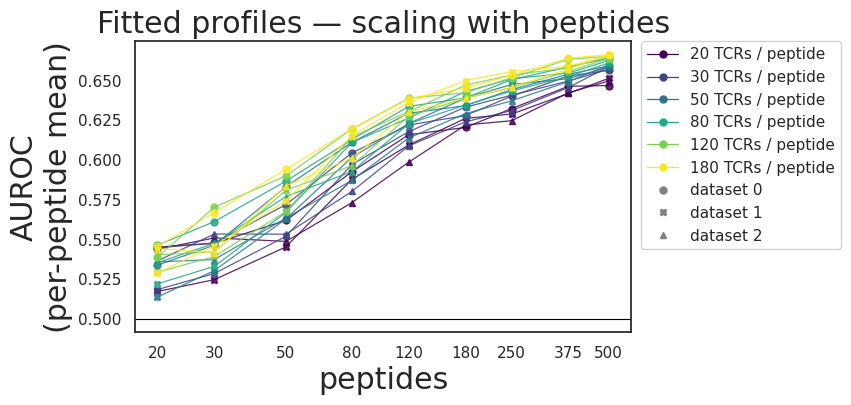

In [35]:
# Figure 1: fitted profiles — scaling with peptides
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

df_r = pd.read_csv("data/scaling_results.tsv", sep="\t")
df_fp = df_r[df_r.model == "fitted profiles"]

tcr_vals = sorted(df_fp.tcrs.unique())
cfg_markers = {0: "o", 1: "X", 2: "^"}
cmap = plt.cm.viridis
tcr_colors = {t: cmap(i / (len(tcr_vals) - 1)) for i, t in enumerate(tcr_vals)}

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axhline(0.5, color="black", lw=0.8, ls="-", zorder=0)

for t in tcr_vals:
    for cfg in sorted(df_fp.cfg.unique()):
        sub = df_fp[(df_fp.tcrs == t) & (df_fp.cfg == cfg)].sort_values("peps")
        ax.plot(sub.peps, sub.auroc, marker=cfg_markers[cfg], color=tcr_colors[t],
                ms=5, lw=0.9, alpha=0.85)

h_tcr = [Line2D([], [], color=tcr_colors[t], marker="o", ls="-", ms=5, lw=0.9,
                label=f"{t} TCRs / peptide") for t in tcr_vals]
h_cfg = [Line2D([], [], color="grey", marker=cfg_markers[c], ls="none", ms=5,
                label=f"dataset {c}") for c in sorted(cfg_markers)]
ax.legend(handles=h_tcr + h_cfg, fontsize=11, bbox_to_anchor=(1.02, 1), loc="upper left",
          borderaxespad=0, framealpha=0.9)
ax.set_xscale("log"); ax.set_xticks(sorted(df_fp.peps.unique()))
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.tick_params(axis="both", labelsize=11)
ax.set_xlabel("peptides"); ax.set_ylabel("AUROC\n(per-peptide mean)")
ax.set_title("Fitted profiles — scaling with peptides")
fig.tight_layout(); plt.show()

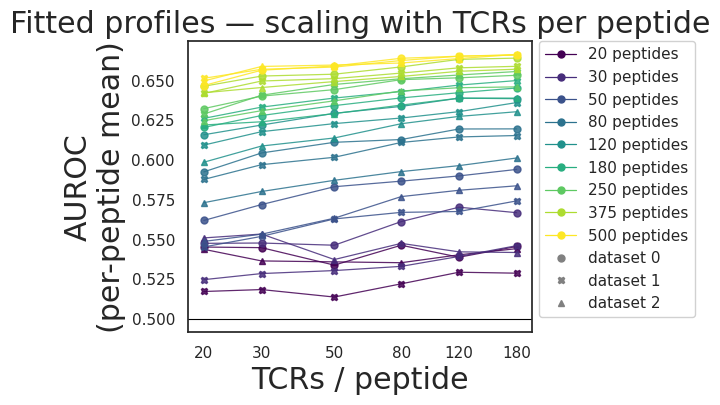

In [36]:
# Figure 2: fitted profiles — scaling with TCRs per peptide
pep_vals = sorted(df_fp.peps.unique())
pep_colors = {p: cmap(i / (len(pep_vals) - 1)) for i, p in enumerate(pep_vals)}

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(0.5, color="black", lw=0.8, ls="-", zorder=0)

for p in pep_vals:
    for cfg in sorted(df_fp.cfg.unique()):
        sub = df_fp[(df_fp.peps == p) & (df_fp.cfg == cfg)].sort_values("tcrs")
        ax.plot(sub.tcrs, sub.auroc, marker=cfg_markers[cfg], color=pep_colors[p],
                ms=5, lw=0.9, alpha=0.85)

h_pep = [Line2D([], [], color=pep_colors[p], marker="o", ls="-", ms=5, lw=0.9,
                label=f"{p} peptides") for p in pep_vals]
h_cfg = [Line2D([], [], color="grey", marker=cfg_markers[c], ls="none", ms=5,
                label=f"dataset {c}") for c in sorted(cfg_markers)]
ax.legend(handles=h_pep + h_cfg, fontsize=11, bbox_to_anchor=(1.02, 1), loc="upper left",
          borderaxespad=0, framealpha=0.9, ncol=1)
ax.set_xscale("log"); ax.set_xticks(sorted(df_fp.tcrs.unique()))
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.tick_params(axis="both", labelsize=11)
ax.set_xlabel("TCRs / peptide"); ax.set_ylabel("AUROC\n(per-peptide mean)")
ax.set_title("Fitted profiles — scaling with TCRs per peptide")
fig.tight_layout(); plt.show()

In [37]:
# Power-law fit: log(AUROC) ~ log(peptides) + log(TCRs/pep), random intercept per config
import statsmodels.formula.api as smf

df_pl = df_fp[["cfg", "peps", "tcrs", "auroc"]].copy()
df_pl["log_p"] = np.log(df_pl["peps"])
df_pl["log_t"] = np.log(df_pl["tcrs"])
df_pl["log_auroc"] = np.log(df_pl["auroc"])

model = smf.mixedlm("log_auroc ~ log_p + log_t", df_pl, groups=df_pl["cfg"])
result = model.fit()
print(result.summary())

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: log_auroc
No. Observations: 162     Method:             REML     
No. Groups:       3       Scale:              0.0003   
Min. group size:  54      Log-Likelihood:     400.0949 
Max. group size:  54      Converged:          Yes      
Mean group size:  54.0                                 
-------------------------------------------------------
            Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept   -0.890    0.011 -79.405 0.000 -0.912 -0.868
log_p        0.069    0.001  50.843 0.000  0.067  0.072
log_t        0.015    0.002   7.851 0.000  0.011  0.019
Group Var    0.000    0.004                            



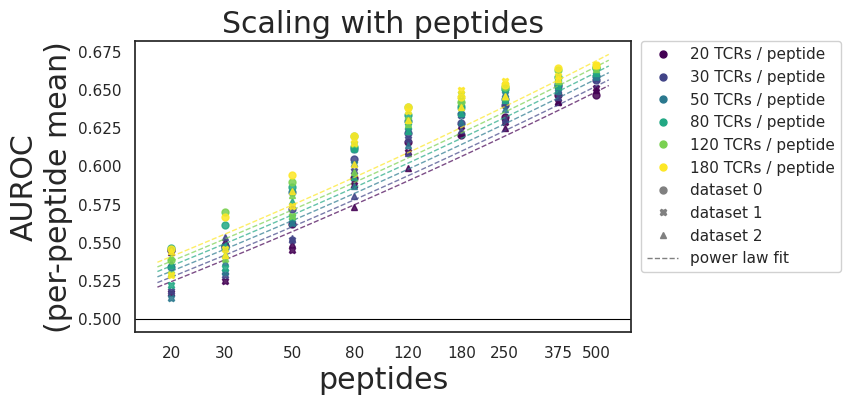

In [38]:
# Figure 1v2: scaling with peptides + power law fit
def powerlaw(p, t):
    return np.exp(-0.885) * (p ** 0.066) * (t ** 0.014)

p_smooth = np.geomspace(18, 550, 100)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axhline(0.5, color="black", lw=0.8, ls="-", zorder=0)

for t in tcr_vals:
    for cfg in sorted(df_fp.cfg.unique()):
        sub = df_fp[(df_fp.tcrs == t) & (df_fp.cfg == cfg)].sort_values("peps")
        ax.plot(sub.peps, sub.auroc, marker=cfg_markers[cfg], color=tcr_colors[t],
                ms=5, lw=0, alpha=0.85)
    ax.plot(p_smooth, powerlaw(p_smooth, t), ls="--", color=tcr_colors[t], lw=1.0, alpha=0.7)

h_tcr = [Line2D([], [], color=tcr_colors[t], marker="o", ls="none", ms=5,
                label=f"{t} TCRs / peptide") for t in tcr_vals]
h_cfg = [Line2D([], [], color="grey", marker=cfg_markers[c], ls="none", ms=5,
                label=f"dataset {c}") for c in sorted(cfg_markers)]
h_fit = [Line2D([], [], color="grey", ls="--", lw=1.0, label="power law fit")]
ax.legend(handles=h_tcr + h_cfg + h_fit, fontsize=11, bbox_to_anchor=(1.02, 1),
          loc="upper left", borderaxespad=0, framealpha=0.9)
ax.set_xscale("log"); ax.set_xticks(sorted(df_fp.peps.unique()))
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.tick_params(axis="both", labelsize=11)
ax.set_xlabel("peptides"); ax.set_ylabel("AUROC\n(per-peptide mean)")
ax.set_title("Scaling with peptides")
fig.tight_layout(); plt.show()

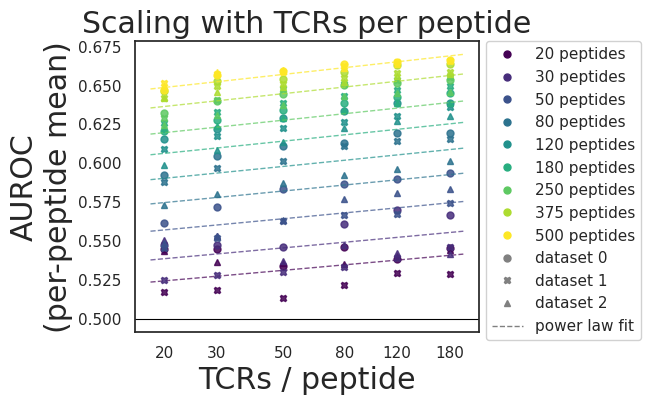

In [39]:
# Figure 2v2: scaling with TCRs per peptide + power law fit
t_smooth = np.geomspace(18, 200, 100)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(0.5, color="black", lw=0.8, ls="-", zorder=0)

for p in pep_vals:
    for cfg in sorted(df_fp.cfg.unique()):
        sub = df_fp[(df_fp.peps == p) & (df_fp.cfg == cfg)].sort_values("tcrs")
        ax.plot(sub.tcrs, sub.auroc, marker=cfg_markers[cfg], color=pep_colors[p],
                ms=5, lw=0, alpha=0.85)
    ax.plot(t_smooth, powerlaw(p, t_smooth), ls="--", color=pep_colors[p], lw=1.0, alpha=0.7)

h_pep = [Line2D([], [], color=pep_colors[p], marker="o", ls="none", ms=5,
                label=f"{p} peptides") for p in pep_vals]
h_cfg = [Line2D([], [], color="grey", marker=cfg_markers[c], ls="none", ms=5,
                label=f"dataset {c}") for c in sorted(cfg_markers)]
h_fit = [Line2D([], [], color="grey", ls="--", lw=1.0, label="power law fit")]
ax.legend(handles=h_pep + h_cfg + h_fit, fontsize=11, bbox_to_anchor=(1.02, 1),
          loc="upper left", borderaxespad=0, framealpha=0.9)
ax.set_xscale("log"); ax.set_xticks(sorted(df_fp.tcrs.unique()))
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.tick_params(axis="both", labelsize=11)
ax.set_xlabel("TCRs / peptide"); ax.set_ylabel("AUROC\n(per-peptide mean)")
ax.set_title("Scaling with TCRs per peptide")
fig.tight_layout(); plt.show()

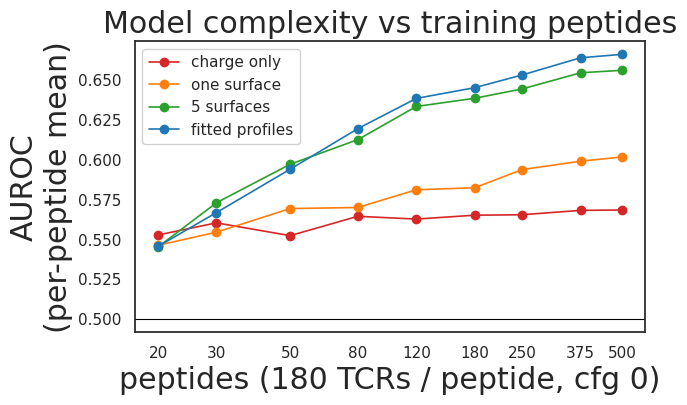

In [40]:
# Figure 3: model comparison — scaling with peptides (cfg 0, 180 TCRs/peptide)
model_colors = {"charge only": "#d62728", "one surface": "#ff7f0e",
                "5 surfaces": "#2ca02c", "fitted profiles": "#1f77b4"}

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(0.5, color="black", lw=0.8, ls="-", zorder=0)

for mk in SCALE_MODEL_ORDER:
    sub = df_r[(df_r.model == mk) & (df_r.cfg == 0) & (df_r.tcrs == 180)].sort_values("peps")
    ax.plot(sub.peps, sub.auroc, marker="o", color=model_colors[mk],
            ms=6, lw=1.2, label=mk)

ax.legend(fontsize=11, loc="upper left", framealpha=0.9)
ax.set_xscale("log"); ax.set_xticks(SCALING_PEPS)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.tick_params(axis="both", labelsize=11)
ax.set_xlabel("peptides (180 TCRs / peptide, cfg 0)")
ax.set_ylabel("AUROC\n(per-peptide mean)")
ax.set_title("Model complexity vs training peptides")
fig.tight_layout(); plt.show()

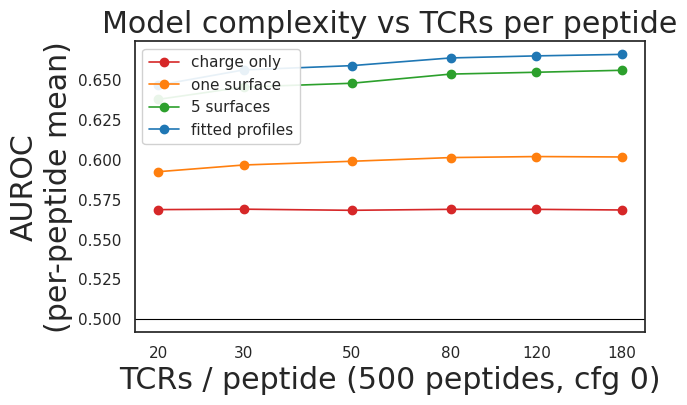

In [41]:
# Figure 4: model comparison — scaling with TCRs (cfg 0, 500 peptides)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(0.5, color="black", lw=0.8, ls="-", zorder=0)

for mk in SCALE_MODEL_ORDER:
    sub = df_r[(df_r.model == mk) & (df_r.cfg == 0) & (df_r.peps == 500)].sort_values("tcrs")
    ax.plot(sub.tcrs, sub.auroc, marker="o", color=model_colors[mk],
            ms=6, lw=1.2, label=mk)

ax.legend(fontsize=11, loc="upper left", framealpha=0.9)
ax.set_xscale("log"); ax.set_xticks(SCALING_TCRS)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.tick_params(axis="both", labelsize=11)
ax.set_xlabel("TCRs / peptide (500 peptides, cfg 0)")
ax.set_ylabel("AUROC\n(per-peptide mean)")
ax.set_title("Model complexity vs TCRs per peptide")
fig.tight_layout(); plt.show()

In [42]:
# Refit 4 models at cfg0, t=180 and t=20, save per-row holdout scores, bootstrap CIs
import gc
from scipy.stats import rankdata

def holdout_row_scores(m):
    """Score holdout at row level -> (peptide_ids, scores, labels)."""
    S_h = build_all_S(E_HOLDOUT, m["pose"],
                      surfaces=m.get("surfaces_def", SURFACES),
                      sigma_override=m.get("sigma_override"), label="", quiet=True)
    _, grp_h = groups(E_HOLDOUT, np.arange(E_HOLDOUT["n_row"]))
    sc = score_rows(E_HOLDOUT, S_h, m, grp_h)
    peps = np.concatenate([np.full(len(g), E_HOLDOUT["rows_p"][g[0]]) for g in grp_h])
    labels = np.concatenate([E_HOLDOUT["Y"][g] for g in grp_h])
    scores = np.concatenate(sc)
    del S_h; gc.collect()
    return peps, scores, labels

def pep_bootstrap_auroc(peps, scores, labels, n_boot=1000, seed=42):
    """Two-level peptide bootstrap of per-peptide mean AUROC.
    Level 1: resample peptides with replacement.
    Level 2: resample rows within each peptide with replacement."""
    rng = np.random.default_rng(seed)
    unique_p = np.unique(peps)
    grp = {p: np.flatnonzero(peps == p) for p in unique_p}
    n_pep = len(unique_p)
    boots = []
    for _ in range(n_boot):
        sampled = rng.choice(unique_p, size=n_pep, replace=True)
        per_pep = []
        for p in sampled:
            idx = grp[p]
            bi = rng.choice(idx, size=len(idx), replace=True)
            y, s = labels[bi], scores[bi]
            if y.min() == y.max():
                continue
            r = rankdata(s)
            n1, n0 = y.sum(), (1 - y).sum()
            per_pep.append((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
        if per_pep:
            boots.append(np.mean(per_pep))
    boots = np.array(boots)
    return boots.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)

_save_globals()
boot_results = []
t0 = time.time()
BOOT_TCRS = [180, 20]

for t_fixed in BOOT_TCRS:
    for mk in SCALE_MODEL_ORDER:
        for p in SCALING_PEPS:
            fname = f"data/scaling/cfg0_p{p}_t{t_fixed}.tsv"
            if not os.path.exists(fname):
                print(f"  SKIP cfg0 p{p:>3d} t{t_fixed} {mk} — file missing")
                continue
            df_s = pd.read_csv(fname, sep="\t")
            install_training_data(df_s)
            mcfg = SCALE_MODELS[mk]
            with contextlib.redirect_stdout(io.StringIO()):
                set_geometry(mcfg["pose"], surfaces=mcfg["surfaces"])
                if mk == "fitted profiles":
                    A_seed = fit_at([ALL6], [W9_PRIOR], "warm")
                    A = alternate("A", [ALL6], [W9_PRIOR], shared=True, seed=A_seed)
                    W_A = A["ws"][0]
                    W_B = expand_ws([W_A] * K_PROFILES, PROF_MAP)
                    res = alternate("B", SURF5, W_B, shared=False, prof_map=PROF_MAP)
                else:
                    blocks = [([name], mcfg["w_init"]) for name, _ in mcfg["surfaces"]]
                    res = fit_blocks(blocks, project=mcfg["project"], verbose=False)
            m = as_model(res)
            m.update(pose=mcfg["pose"], surfaces_def=mcfg["surfaces"], sigma_override=None)
            peps_h, scores_h, labels_h = holdout_row_scores(m)
            mean, lo, hi = pep_bootstrap_auroc(peps_h, scores_h, labels_h)
            boot_results.append(dict(model=mk, peps=p, tcrs=t_fixed, mean=mean, lo=lo, hi=hi))
            print(f"  cfg0 p{p:>3d} t{t_fixed:>3d}  {mk:<18s}  {mean:.4f}  [{lo:.4f}, {hi:.4f}]")
            gc.collect()

_restore_globals()
df_boot = pd.DataFrame(boot_results)
df_boot.to_csv("data/scaling_bootstrap.tsv", sep="\t", index=False)
print(f"\n{len(df_boot)} bootstrap results in {(time.time()-t0)/60:.0f}m, saved to data/scaling_bootstrap.tsv")

  cfg0 p 20 t180  charge only         0.5528  [0.5340, 0.5706]
  cfg0 p 30 t180  charge only         0.5604  [0.5407, 0.5801]
  cfg0 p 50 t180  charge only         0.5524  [0.5322, 0.5726]
  cfg0 p 80 t180  charge only         0.5646  [0.5460, 0.5829]
  cfg0 p120 t180  charge only         0.5630  [0.5439, 0.5811]
  cfg0 p180 t180  charge only         0.5654  [0.5481, 0.5828]
  cfg0 p250 t180  charge only         0.5657  [0.5481, 0.5827]
  cfg0 p375 t180  charge only         0.5685  [0.5499, 0.5855]
  cfg0 p500 t180  charge only         0.5686  [0.5500, 0.5859]
  cfg0 p 20 t180  one surface         0.5461  [0.5293, 0.5640]
  cfg0 p 30 t180  one surface         0.5541  [0.5371, 0.5719]
  cfg0 p 50 t180  one surface         0.5691  [0.5531, 0.5853]
  cfg0 p 80 t180  one surface         0.5698  [0.5546, 0.5852]
  cfg0 p120 t180  one surface         0.5810  [0.5662, 0.5963]
  cfg0 p180 t180  one surface         0.5823  [0.5660, 0.5983]
  cfg0 p250 t180  one surface         0.5936  [0.5776, 

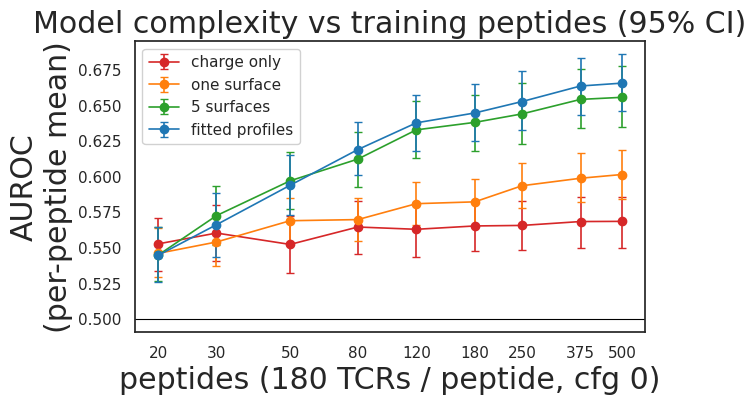

In [43]:
# Figure 5: model comparison with error bars — 180 TCRs/peptide, cfg 0
df_boot = pd.read_csv("data/scaling_bootstrap.tsv", sep="\t")
model_colors = {"charge only": "#d62728", "one surface": "#ff7f0e",
                "5 surfaces": "#2ca02c", "fitted profiles": "#1f77b4"}

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(0.5, color="black", lw=0.8, ls="-", zorder=0)

for mk in SCALE_MODEL_ORDER:
    sub = df_boot[(df_boot.model == mk) & (df_boot.tcrs == 180)].sort_values("peps")
    if sub.empty:
        continue
    x = sub.peps.values
    y = sub["mean"].values
    yerr = [y - sub.lo.values, sub.hi.values - y]
    ax.errorbar(x, y, yerr=yerr, marker="o", color=model_colors[mk],
                ms=6, lw=1.2, capsize=3, label=mk)

ax.legend(fontsize=11, loc="upper left", framealpha=0.9)
ax.set_xscale("log"); ax.set_xticks(SCALING_PEPS)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.tick_params(axis="both", labelsize=11)
ax.set_xlabel("peptides (180 TCRs / peptide, cfg 0)")
ax.set_ylabel("AUROC\n(per-peptide mean)")
ax.set_title("Model complexity vs training peptides (95% CI)")
fig.tight_layout(); plt.show()

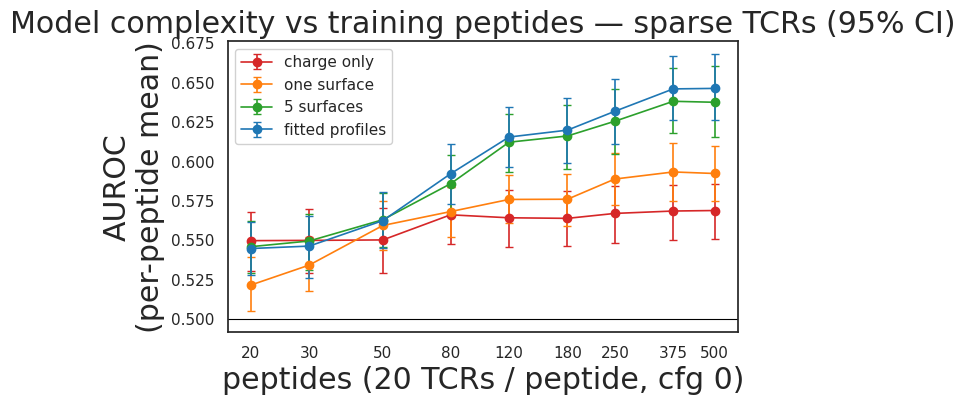

In [44]:
# Figure 6: model comparison with error bars — 20 TCRs/peptide, cfg 0
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(0.5, color="black", lw=0.8, ls="-", zorder=0)

for mk in SCALE_MODEL_ORDER:
    sub = df_boot[(df_boot.model == mk) & (df_boot.tcrs == 20)].sort_values("peps")
    if sub.empty:
        continue
    x = sub.peps.values
    y = sub["mean"].values
    yerr = [y - sub.lo.values, sub.hi.values - y]
    ax.errorbar(x, y, yerr=yerr, marker="o", color=model_colors[mk],
                ms=6, lw=1.2, capsize=3, label=mk)

ax.legend(fontsize=11, loc="upper left", framealpha=0.9)
ax.set_xscale("log"); ax.set_xticks(SCALING_PEPS)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.tick_params(axis="both", labelsize=11)
ax.set_xlabel("peptides (20 TCRs / peptide, cfg 0)")
ax.set_ylabel("AUROC\n(per-peptide mean)")
ax.set_title("Model complexity vs training peptides — sparse TCRs (95% CI)")
fig.tight_layout(); plt.show()

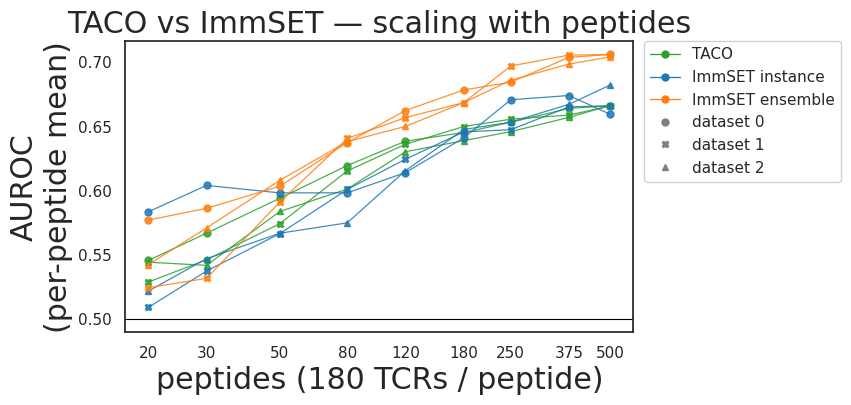

In [45]:
# TACO vs ImmSET scaling comparison (180 TCRs/peptide, 3 configs)
from scipy.stats import rankdata

_df_inst = pd.read_csv("data/immset_ml4h_predictions/instance.tsv", sep="\t")
_df_ens  = pd.read_csv("data/immset_ml4h_predictions/ensemble.tsv", sep="\t")
df_r = pd.read_csv("data/scaling_results.tsv", sep="\t")

def per_peptide_auroc(df, score_col):
    per = []
    for pep, g in df.groupby("peptide"):
        y = g["label"].values
        if y.min() == y.max():
            continue
        s = g[score_col].values
        r = rankdata(s)
        n1, n0 = y.sum(), (1 - y).sum()
        per.append((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
    return float(np.mean(per))

immset_rows = []
for cfg in [0, 1, 2]:
    for p in SCALING_PEPS:
        col_inst = f"p_ImmSET_instance_cfg{cfg}_p{p}_t180"
        if col_inst in _df_inst.columns:
            immset_rows.append(dict(model="ImmSET instance", cfg=cfg, peps=p,
                                    auroc=per_peptide_auroc(_df_inst, col_inst)))
        col_ens = f"p_ImmSET_ensembleV1_cfg{cfg}_p{p}_t180"
        if col_ens in _df_ens.columns:
            immset_rows.append(dict(model="ImmSET ensemble", cfg=cfg, peps=p,
                                    auroc=per_peptide_auroc(_df_ens, col_ens)))
df_immset = pd.DataFrame(immset_rows)

df_taco = df_r[(df_r.model == "fitted profiles") & (df_r.tcrs == 180)].copy()
df_taco["model"] = "TACO"

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axhline(0.5, color="black", lw=0.8, ls="-", zorder=0)

model_colors = {"TACO": "#2ca02c", "ImmSET instance": "#1f77b4", "ImmSET ensemble": "#ff7f0e"}
cfg_markers = {0: "o", 1: "X", 2: "^"}

for mname, color in model_colors.items():
    sub_all = df_taco if mname == "TACO" else df_immset[df_immset.model == mname]
    for cfg in [0, 1, 2]:
        sub = sub_all[sub_all.cfg == cfg].sort_values("peps")
        ax.plot(sub.peps, sub.auroc, marker=cfg_markers[cfg], color=color,
                ms=5, lw=0.9, alpha=0.85)

h_model = [Line2D([], [], color=model_colors[m], marker="o", ls="-", ms=5, lw=0.9,
                  label=m) for m in model_colors]
h_cfg = [Line2D([], [], color="grey", marker=cfg_markers[c], ls="none", ms=5,
                label=f"dataset {c}") for c in [0, 1, 2]]
ax.legend(handles=h_model + h_cfg, fontsize=11, bbox_to_anchor=(1.02, 1),
          loc="upper left", borderaxespad=0, framealpha=0.9)
ax.set_xscale("log"); ax.set_xticks(SCALING_PEPS)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.tick_params(axis="both", labelsize=11)
ax.set_xlabel("peptides (180 TCRs / peptide)")
ax.set_ylabel("AUROC\n(per-peptide mean)")
ax.set_title("TACO vs ImmSET — scaling with peptides")
fig.tight_layout(); plt.show()

Row alignment verified: 33500 rows


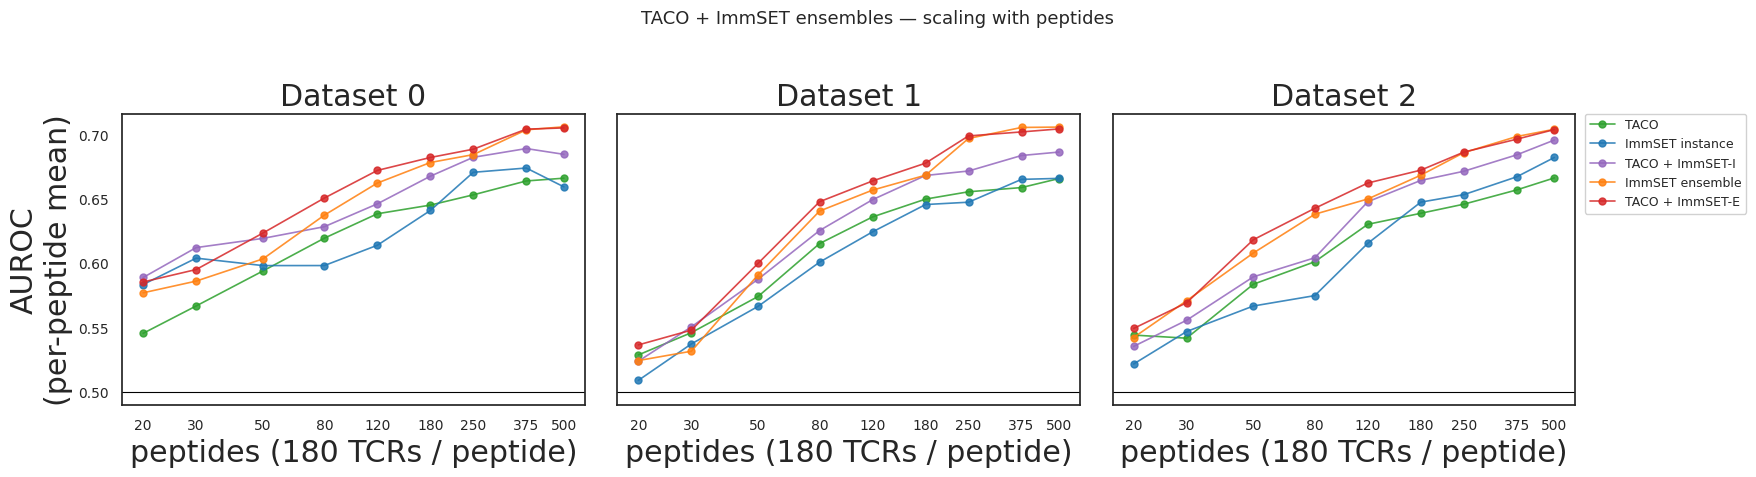

In [46]:
# Ensemble comparisons: TACO + ImmSET (3 figures, one per dataset)
from scipy.stats import rankdata

_df_taco = pd.read_csv("data/taco_holdout_predictions.tsv", sep="\t")
_df_inst = pd.read_csv("data/immset_ml4h_predictions/instance.tsv", sep="\t")
_df_ens  = pd.read_csv("data/immset_ml4h_predictions/ensemble.tsv", sep="\t")

# Verify row alignment
assert list(_df_taco.peptide) == list(_df_inst.peptide), "peptide mismatch: TACO vs ImmSET instance"
assert list(_df_taco.label) == list(_df_inst.label), "label mismatch: TACO vs ImmSET instance"
assert list(_df_taco.peptide) == list(_df_ens.peptide), "peptide mismatch: TACO vs ImmSET ensemble"
print(f"Row alignment verified: {len(_df_taco)} rows")

def _rank_norm(s):
    return rankdata(s) / len(s)

ens_rows = []
for cfg in [0, 1, 2]:
    for p in SCALING_PEPS:
        col_t = f"p_TACO_cfg{cfg}_p{p}_t180"
        col_i = f"p_ImmSET_instance_cfg{cfg}_p{p}_t180"
        col_e = f"p_ImmSET_ensembleV1_cfg{cfg}_p{p}_t180"
        if col_t not in _df_taco.columns:
            continue

        rn_t = _rank_norm(_df_taco[col_t].values)

        ens_rows.append(dict(model="TACO", cfg=cfg, peps=p,
                             auroc=per_peptide_auroc(_df_taco, col_t)))

        if col_i in _df_inst.columns:
            rn_i = _rank_norm(_df_inst[col_i].values)
            ens_rows.append(dict(model="ImmSET instance", cfg=cfg, peps=p,
                                 auroc=per_peptide_auroc(_df_inst, col_i)))
            _df_taco["_ens_ti"] = (rn_t + rn_i) / 2
            ens_rows.append(dict(model="TACO + ImmSET-I", cfg=cfg, peps=p,
                                 auroc=per_peptide_auroc(_df_taco, "_ens_ti")))

        if col_e in _df_ens.columns:
            rn_e = _rank_norm(_df_ens[col_e].values)
            ens_rows.append(dict(model="ImmSET ensemble", cfg=cfg, peps=p,
                                 auroc=per_peptide_auroc(_df_ens, col_e)))
            _df_taco["_ens_te"] = (rn_t + rn_e) / 2
            ens_rows.append(dict(model="TACO + ImmSET-E", cfg=cfg, peps=p,
                                 auroc=per_peptide_auroc(_df_taco, "_ens_te")))

df_ens = pd.DataFrame(ens_rows)

_COLORS = {
    "TACO":            "#2ca02c",
    "ImmSET instance": "#1f77b4",
    "TACO + ImmSET-I": "#9467bd",
    "ImmSET ensemble": "#ff7f0e",
    "TACO + ImmSET-E": "#d62728",
}
_ORDER = list(_COLORS.keys())

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ci, cfg in enumerate([0, 1, 2]):
    ax = axes[ci]
    ax.axhline(0.5, color="black", lw=0.8, ls="-", zorder=0)
    sub_cfg = df_ens[df_ens.cfg == cfg]
    for mname in _ORDER:
        sub = sub_cfg[sub_cfg.model == mname].sort_values("peps")
        if len(sub) == 0:
            continue
        ax.plot(sub.peps, sub.auroc, marker="o", color=_COLORS[mname],
                ms=5, lw=1.2, alpha=0.85, label=mname)
    ax.set_xscale("log"); ax.set_xticks(SCALING_PEPS)
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.tick_params(axis="both", labelsize=10)
    ax.set_xlabel("peptides (180 TCRs / peptide)")
    ax.set_title(f"Dataset {cfg}")
    if ci == 0:
        ax.set_ylabel("AUROC\n(per-peptide mean)")

axes[-1].legend(fontsize=9, bbox_to_anchor=(1.02, 1), loc="upper left",
                borderaxespad=0, framealpha=0.9)
fig.suptitle("TACO + ImmSET ensembles — scaling with peptides", fontsize=13)
fig.tight_layout(); plt.show()

# cleanup temp columns
_df_taco.drop(columns=[c for c in _df_taco.columns if c.startswith("_ens_")],
              inplace=True, errors="ignore")

<a id="cross-allele"></a>

### Cross-allele generalization

The model is trained exclusively on A\*02:01 data.  How well does it transfer to
peptides presented by other HLA alleles?  For each training-set size (peptide count,
180 TCRs/peptide), we score nine holdout allele datasets — three HLA-A, three HLA-B,
three HLA-C — and report per-peptide mean AUROC.  One figure per dataset configuration.

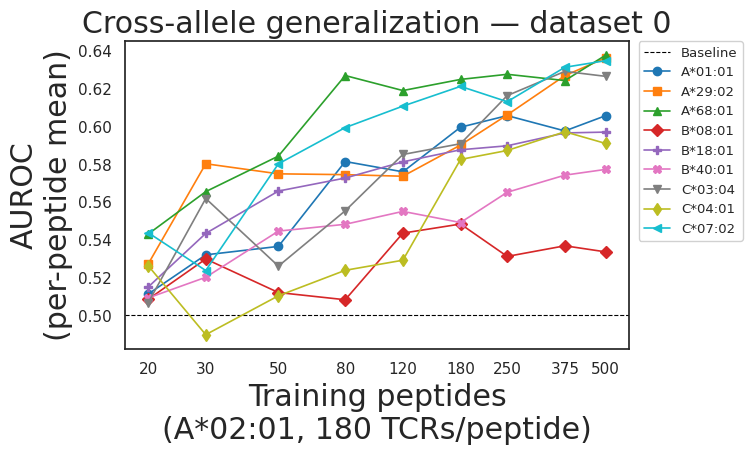

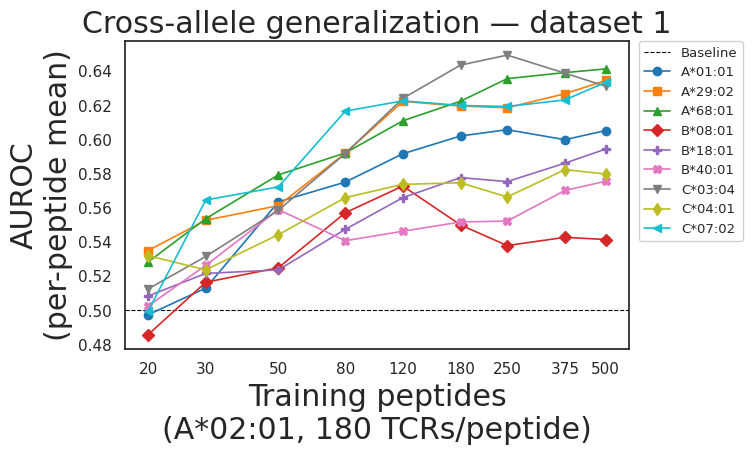

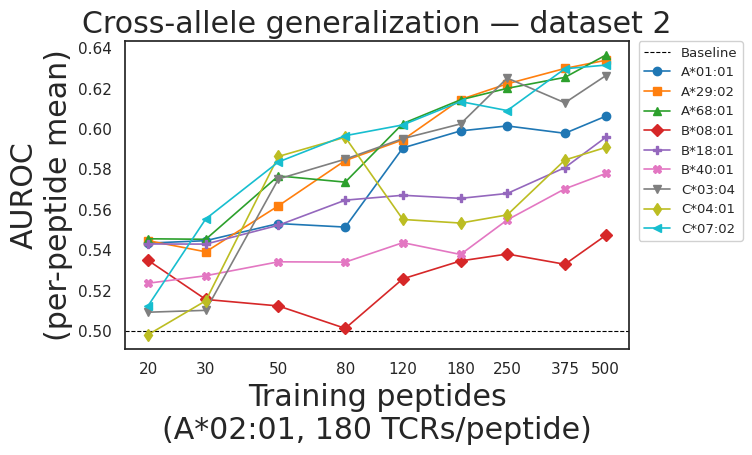

In [47]:
# Cross-allele generalisation: AUROC on holdout alleles vs training peptide count
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

df_xa = pd.read_csv("data/scaling_cross_allele.tsv", sep="\t")

ALLELE_COLORS = {
    "A*01:01": "#1f77b4", "A*29:02": "#ff7f0e", "A*68:01": "#2ca02c",
    "B*08:01": "#d62728", "B*18:01": "#9467bd", "B*40:01": "#e377c2",
    "C*03:04": "#7f7f7f", "C*04:01": "#bcbd22", "C*07:02": "#17becf",
}
ALLELE_MARKERS = {
    "A*01:01": "o", "A*29:02": "s", "A*68:01": "^",
    "B*08:01": "D", "B*18:01": "P", "B*40:01": "X",
    "C*03:04": "v", "C*04:01": "d", "C*07:02": "<",
}

for cfg in sorted(df_xa.cfg.unique()):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.axhline(0.5, color="black", lw=0.8, ls="--", zorder=0, label="Baseline")

    for allele in ALLELE_COLORS:
        sub = df_xa[(df_xa.cfg == cfg) & (df_xa.allele == allele)].sort_values("peps")
        if sub.empty:
            continue
        ax.plot(sub.peps, sub.auroc,
                marker=ALLELE_MARKERS[allele], color=ALLELE_COLORS[allele],
                ms=6, lw=1.2, label=allele)

    ax.legend(fontsize=9.5, bbox_to_anchor=(1.02, 1), loc="upper left",
              borderaxespad=0, framealpha=0.9)
    ax.set_xscale("log")
    ax.set_xticks(sorted(df_xa.peps.unique()))
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.tick_params(axis="both", labelsize=11)
    ax.set_xlabel("Training peptides\n(A*02:01, 180 TCRs/peptide)")
    ax.set_ylabel("AUROC\n(per-peptide mean)")
    ax.set_title(f"Cross-allele generalization — dataset {cfg}")
    fig.tight_layout()
    plt.show()
